# **PART 0: TECHNICAL INITIATION**

## **0.1. Import Libraries**

In [ ]:
# silence warnings
import warnings
warnings.filterwarnings('ignore')

# basic libraries
import numpy as np
import pandas as pd

# basic python utilities
import sklearn
import math
import time
import textwrap
from typing import List, Dict, Tuple
from collections import Counter, defaultdict
import scipy.stats as stats
from scipy.stats import chi2_contingency, randint, shapiro

# plotting and visualization
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt

# preprocessing and encoding
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, MinMaxScaler
!pip install category_encoders

# missing values
from sklearn.impute import SimpleImputer, KNNImputer

# feature engineering
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel

# models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV, validation_curve, StratifiedKFold

# dimensionality reduction
from sklearn.decomposition import PCA

# evaluation
from sklearn import metrics
from sklearn.metrics import accuracy_score, classification_report, auc, roc_auc_score, mean_squared_error, confusion_matrix, roc_curve, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, make_scorer
from sklearn.inspection import permutation_importance

# model selection
from sklearn.model_selection import cross_val_score, GridSearchCV, train_test_split, KFold, RandomizedSearchCV

from google.colab import files

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 2.4 MB/s eta 0:00:00


## **0.2 Runtime Count**

In [ ]:
start_time = time.time()

# **PART 1: BUSINESS UNDERSTANDING**

## **Goal Definition & Target Variable**

The goal of this project is to build a binary classification model that predicts whether a mortgage loan application will be approved (class 1) or not approved (class 0), based on various features describing the applicant’s background and the details of their loan request.

Understanding the loan approval process is critical for financial institutions to manage risk, improve customer service, and streamline decision-making. Accurate prediction models can help automate the approval pipeline, reduce manual reviews, and ensure fair and consistent decisions.

The dataset includes both known and anonymized features, which may represent sensitive or proprietary attributes. Therefore, part of the challenge lies in interpreting the influence of anonymized variables, identifying the most informative features, and mitigating bias.

Success will be measured by the model’s ability to generalize to unseen data — maximizing classification performance through appropriate data preprocessing, feature engineering, model selection, and evaluation.

# **PART 2: DATA DISCOVERY**

## **2.1 Data Load**

In [ ]:
# Data files are expected in the local data/ directory.
# Download or obtain the course dataset before running this notebook.


Mounted at /content/drive


In [ ]:
# Load training and test datasets from local paths
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

train_original = train.copy()
test_original = test.copy()


## **2.2 Variables Meaning**





> '**ID**' = ID of loan application | *not a feature*


---


> '**agency**' = regulatory agency that supervise the bank | *categorial*

---



> '**loan_type**'= type of loan requested | *categorial*
---


> '**property_type**' = type of property being financed | *categorial*

---


> '**loan_purpose**' = such as purchase, improvement or refinancing | *categorial*
---


> '**owner_occupancy**' = Denotes whether the property is occupied by the owner as a principal residence or rented out | *categorial*
---


> '**loan_amount**' = in thousand of USD | *numeric*

---


> '**preapproval**' = whether the loan application was pre-approved or if preapproval was not applicable | *categorial*
---


> '**msamd**' = location of the property | *categorial*

---

> '**county**' = location of the property | *categorial*
---

> '**county_code**' = location of the property | *categorial*

---

> '**census_tract_number**' = "CTN", location of the property | *categorial*
---

> '**applicant_ethnicity**' = ethnicity of the loan applicant | *categorial*
---

> '**applicant_race_name_1/2/3**' = racial identity of the loan applicant | *categorial*

---

> '**co_applicant_ethnicity**' = Ethnicity of the co-applicant (if any) | *categorial*

---

> '**co_applicant_race_name_1/2/3**' = Racial identity of the co-applicant | *categorial*

---

> '**applicant_sex**', 'co_applicant_sex' | *categorial*

---

> '**applicant_income**' = in thousands of USD | *numeric*

---

> '**lien_status**' = "mashkanta" | *categorial*

---

> '**population**' = population in CTN | *numeric*

---

> '**minority_population**' = percentage of minority population in CTN | *numeric*

---

> '**hud_median_family_income**' = The median family income in CTN, as defined by the states authority (HUD) | *numeric*

---

> '**tract_to_msamd_income**' = the ratio of the median family income in the CTN and in MSA\MD area | *numeric*

---

> '**number_of_owner_occupied_units**' = number of owner-occupied housing units in the CTN | *numeric*

---

> **anonymous cols: 'A'** | probably *numeric*, **'B'** | probably *numeric*, **'C'** | probably *numeric*, **'D'** | probably *categorial*
---

> **'label'** = the outcome of the loan application | *binary*


## **2.3 Train Set Structure Analysis**

### **2.3.1 Train - Initial Display**

In [ ]:
train

,ID,agency,loan_type,property_type,loan_purpose,owner_occupancy,loan_amount,preapproval,msamd,county,...,population,minority_population,hud_median_family_income,tract_to_msamd_income,number_of_owner_occupied_units,A,B,C,D,label
0,187616,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,Refinancing,Owner-occupied as a principal dwelling,160.0,Not applicable,"Lakeland, Winter Haven - FL",Polk County,...,5631.0,56.349998,52500.0,105.989998,1334.0,169.130727,NaN,2036.0,la,0
1,599925,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,Refinancing,Owner-occupied as a principal dwelling,235.0,NaN,"North Port, Sarasota, Bradenton - FL",Sarasota County,...,8958.0,13.610000,65500.0,89.489998,3015.0,170.521576,-3.525982,4461.0,la,0
2,139007,National Credit Union Administration,Conventional,One-to-four family dwelling (other than manufa...,Refinancing,Owner-occupied as a principal dwelling,311.0,Not applicable,"Tampa, St. Petersburg, Clearwater - FL",Hillsborough County,...,2919.0,8.050000,59800.0,191.929993,986.0,170.903815,-1.188552,1408.0,gh,1
3,437680,Department of Housing and Urban Development,FHA-insured,One-to-four family dwelling (other than manufa...,NaN,Not owner-occupied as a principal dwelling,174.0,Not applicable,"Miami, Miami Beach, Kendall - FL",Miami-Dade County,...,8960.0,96.349998,51800.0,NaN,1603.0,170.038499,12.932775,1857.0,le,0
4,445662,Consumer Financial Protection Bureau,Conventional,Manufactured housing,Home improvement,Owner-occupied as a principal dwelling,38.0,Not applicable,"West Palm Beach, Boca Raton, Delray Beach - FL",Palm Beach County,...,4055.0,14.350000,NaN,158.820007,1592.0,168.259331,16.068656,1848.0,le,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293659,574505,National Credit Union Administration,Conventional,One-to-four family dwelling (other than manufa...,Refinancing,Not owner-occupied as a principal dwelling,NaN,Not applicable,Gainesville - FL,Alachua County,...,5520.0,57.880001,65200.0,52.810001,248.0,168.061412,6.987016,1094.0,gh,0
293660,521049,Department of Housing and Urban Development,FHA-insured,One-to-four family dwelling (other than manufa...,Home purchase,Owner-occupied as a principal dwelling,307.0,Not applicable,"Fort Lauderdale, Pompano Beach, Deerfield Beac...",Broward County,...,4352.0,50.900002,64100.0,101.980003,940.0,169.279250,8.319260,1384.0,la,1
293661,547149,Consumer Financial Protection Bureau,NaN,One-to-four family dwelling (other than manufa...,NaN,Owner-occupied as a principal dwelling,6.0,Not applicable,"Orlando, Kissimmee, Sanford - FL",Osceola County,...,8568.0,63.830002,58400.0,97.110001,1872.0,169.053557,17.993804,2432.0,la,0
293662,539623,NaN,Conventional,One-to-four family dwelling (other than manufa...,Refinancing,Not owner-occupied as a principal dwelling,280.0,Not applicable,NaN,Broward County,...,NaN,80.410004,64100.0,172.770004,1419.0,NaN,13.377224,NaN,gj,0


### **2.3.2 Train - Dataset size**

In [ ]:
# print the size of the data
print(f"The size of the train data set : {train.shape[0]} rows and {train.shape[1]} columns")

The size of the train data set : 293664 rows and 34 columns


### **2.3.3 Train - Basic Cols Information**

In [ ]:
# create basic cols info function
def detailed_structure_analysis(df, name="Data", categorical_threshold=15):
    # create a table of basic data for each col
    summary = pd.DataFrame({
        'Column': df.columns,
        'Dtype': df.dtypes,
        'Missing Values': df.isnull().sum(),
        'Missing %': df.isnull().mean() * 100,
        'Unique Values': df.nunique()
    }).reset_index(drop=True)

    # automatic classify column type
    def classify_col(col, dtype, nunique):
        if pd.api.types.is_bool_dtype(dtype):
            return 'Boolean'
        elif pd.api.types.is_numeric_dtype(dtype):
            return 'Categorical' if nunique <= categorical_threshold else 'Numerical'
        elif pd.api.types.is_object_dtype(dtype) or pd.api.types.is_categorical_dtype(dtype):
            return 'Categorical'
        else:
            return 'Other'

    # clssify each row
    summary['Automatic Feature Type'] = [
        classify_col(col, row['Dtype'], row['Unique Values'])
        for col, row in zip(summary['Column'], summary.to_dict('records'))
    ]

    # sort by % missing values
    summary = summary.sort_values(by='Missing %', ascending=False).reset_index(drop=True)

    print(f"======== {name.upper()} STRUCTURE ANALYSIS ========")
    display(summary)

detailed_structure_analysis(train, name="Train")

======== TRAIN STRUCTURE ANALYSIS ========


,Column,Dtype,Missing Values,Missing %,Unique Values,Automatic Feature Type
0,co_applicant_race_name_3,object,293634,99.989784,5,Categorical
1,applicant_race_name_3,object,293508,99.946878,5,Categorical
2,co_applicant_race_name_2,object,293120,99.814754,5,Categorical
3,applicant_race_name_2,object,291685,99.326101,5,Categorical
4,applicant_income,float64,27595,9.396794,1647,Numerical
5,msamd,object,22054,7.509943,24,Categorical
6,number_of_owner_occupied_units,float64,20814,7.087692,1909,Numerical
7,hud_median_family_income,float64,20034,6.822082,25,Numerical
8,loan_purpose,object,19085,6.498924,3,Categorical
9,B,float64,18803,6.402896,274861,Numerical


## **2.4 Train Set Statistical Summary**

### **2.4.1 Train Numeric Cols - Statistics**

In [ ]:
# calculate count, mean, std, min-max,
def statistical_summary(df, name="Data"):
    print(f"======== {name.upper()} STATISTICAL SUMMARY ========")
    print("\n--- Numerical Features ---")
    display(df.describe().T)

statistical_summary(train, name="Train")

======== TRAIN STATISTICAL SUMMARY ========

--- Numerical Features ---


,count,mean,std,min,25%,50%,75%,max
ID,293664.0,367898.357007,191467.661195,0.000000,202348.750000,413311.500000,527131.250000,665533.000000
loan_amount,279914.0,210.961224,974.277419,1.000000,99.000000,166.000000,248.000000,312000.000000
county_code,282754.0,71.642753,37.156813,1.000000,33.000000,86.000000,101.000000,133.000000
census_tract_number,279167.0,670.583199,1799.791881,1.000000,90.340000,167.160000,404.010000,9901.000000
applicant_income,266069.0,101.404459,495.573291,1.000000,44.000000,67.000000,107.000000,141700.000000
population,280999.0,6537.524849,4403.114574,0.000000,3983.000000,5562.000000,7559.000000,38169.000000
minority_population,280472.0,37.815192,25.645425,0.000000,17.049999,32.259998,53.750000,100.000000
hud_median_family_income,273630.0,59729.019479,5453.195897,42200.000000,57900.000000,59800.000000,64300.000000,68500.000000
tract_to_msamd_income,276163.0,111.952855,41.684103,0.000000,84.480003,104.660004,132.929993,507.470001
number_of_owner_occupied_units,272850.0,1682.504673,1333.217559,0.000000,984.000000,1405.000000,2018.000000,19529.000000


======= DATA – NUMERIC DISTRIBUTIONS =======


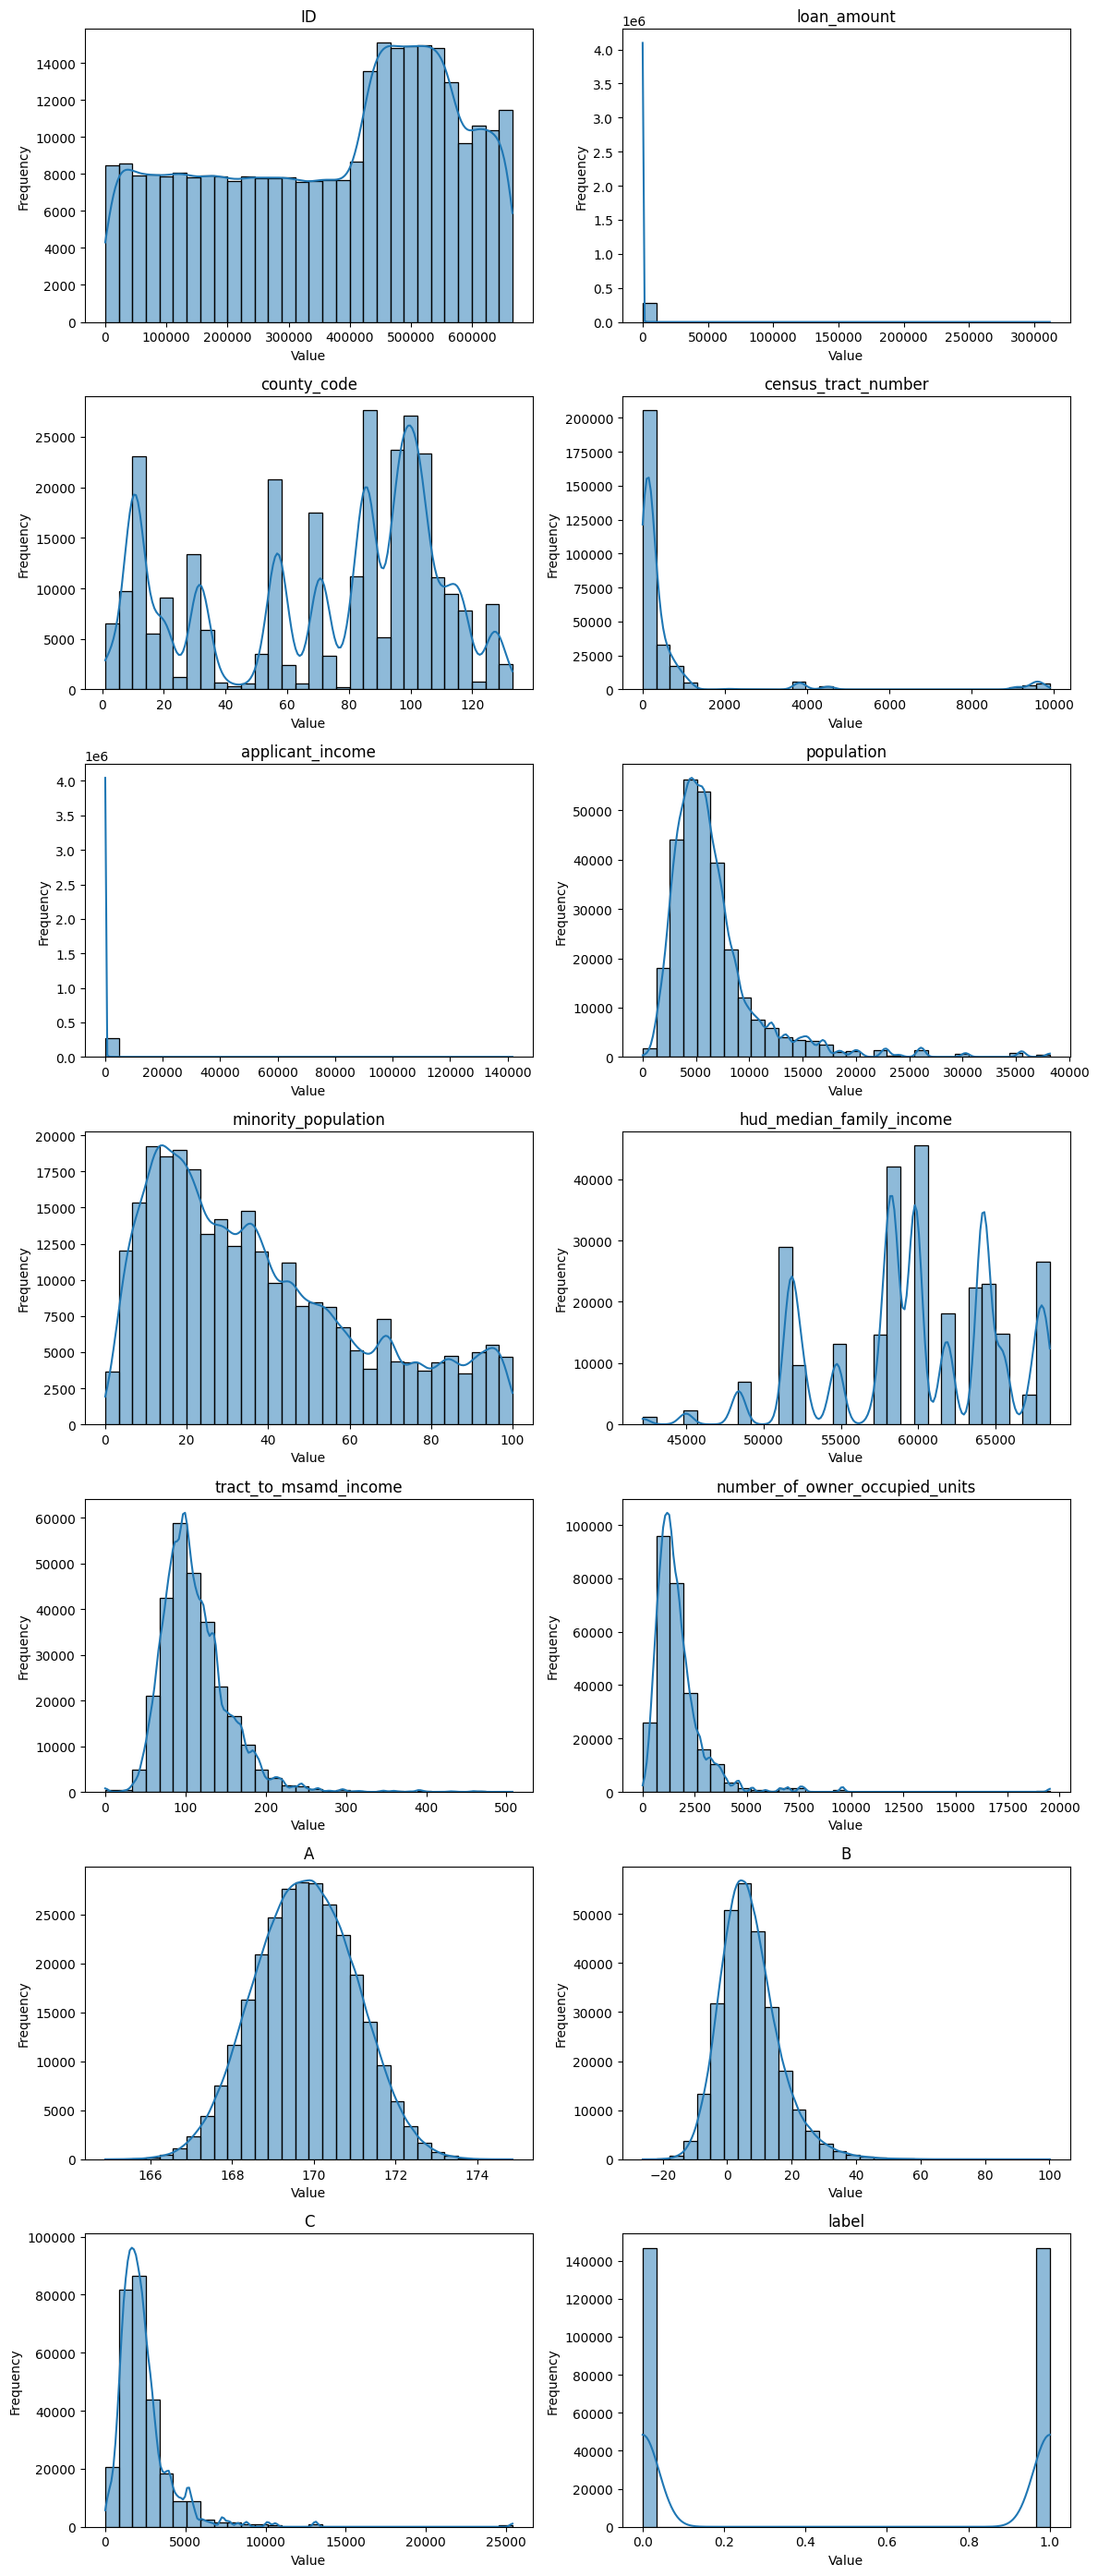

In [ ]:
# create distribution histogram for numerical features
def plot_numeric_distributions(df, bins=30, name="Data"):
    numeric_cols = df.select_dtypes(include=['number']).columns
    num_plots = len(numeric_cols)

    print(f"======= {name.upper()} – NUMERIC DISTRIBUTIONS =======")

    ncols = 2
    nrows = math.ceil(num_plots / ncols)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 4 * nrows))
    axes = axes.flatten()

    # create histograms
    for i, col in enumerate(numeric_cols):
        sns.histplot(df[col].dropna(), bins=bins, ax=axes[i], kde=True)
        axes[i].set_title(col)
        axes[i].set_xlabel("Value")
        axes[i].set_ylabel("Frequency")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_numeric_distributions(train)

### **2.4.2 Train Categoric Cols - Statistics**

======= TRAIN CATEGORICAL COUNTS =======


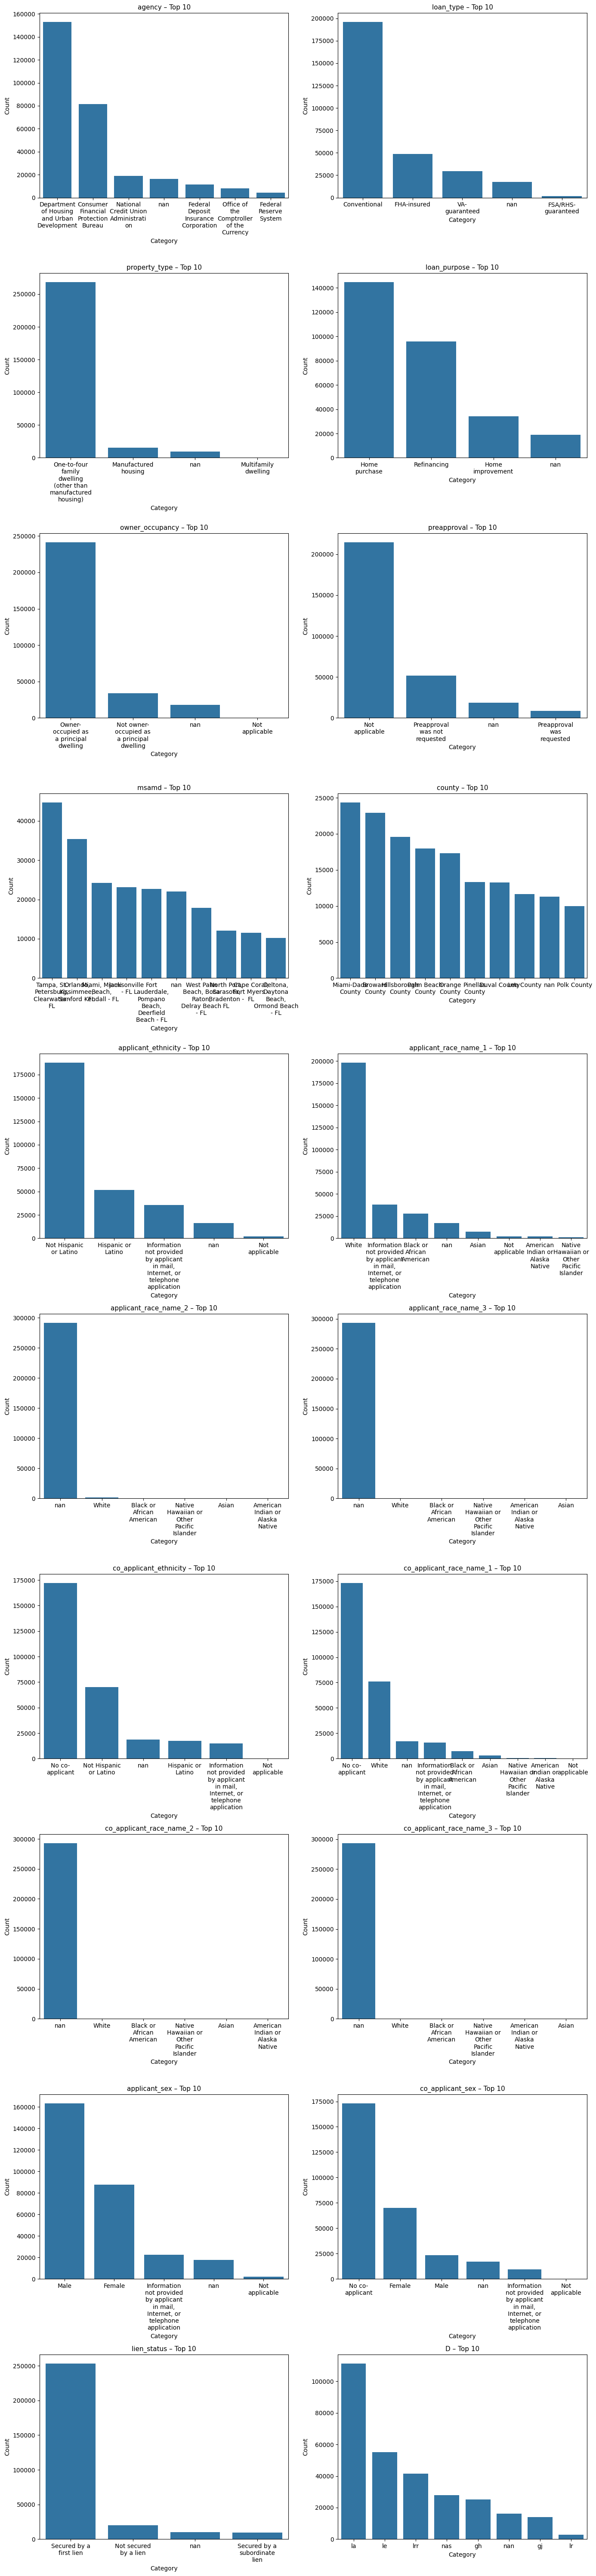

In [ ]:
# create distribution histogram for categorical features
def plot_categorical_counts(df, max_categories=10, name="Data"):
    cat_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns
    num_plots = len(cat_cols)

    print(f"======= {name.upper()} CATEGORICAL COUNTS =======")

    ncols = 2
    nrows = math.ceil(num_plots / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 6 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(cat_cols):
        counts = df[col].value_counts(dropna=False).head(max_categories)
        labels = [textwrap.fill(str(label), width=12) for label in counts.index]
        sns.barplot(x=labels, y=counts.values, ax=axes[i])
        axes[i].set_title(f"{col} – Top {max_categories}", fontsize=11)
        axes[i].set_ylabel("Count")
        axes[i].set_xlabel("Category")
        axes[i].tick_params(axis='x', rotation=0)

    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_categorical_counts(train, name="Train")

## **2.5 Test Set Structure Analysis**

### **2.5.1 Test - Initial Display**

In [ ]:
test

,ID,agency,loan_type,property_type,loan_purpose,owner_occupancy,loan_amount,preapproval,msamd,county,...,lien_status,population,minority_population,hud_median_family_income,tract_to_msamd_income,number_of_owner_occupied_units,A,B,C,D
0,165673,Consumer Financial Protection Bureau,Conventional,One-to-four family dwelling (other than manufa...,Home purchase,Owner-occupied as a principal dwelling,550.0,Not applicable,Tallahassee - FL,Leon County,...,Secured by a first lien,6827.0,21.219999,68500.0,190.009995,2292.0,166.015781,-4.834337,2635.0,le
1,381661,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,Home purchase,Owner-occupied as a principal dwelling,186.0,Preapproval was not requested,"North Port, Sarasota, Bradenton - FL",Sarasota County,...,Secured by a first lien,3906.0,27.600000,65500.0,76.099998,963.0,NaN,-1.254707,1774.0,lrr
2,648587,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,Home improvement,Owner-occupied as a principal dwelling,241.0,Not applicable,Jacksonville - FL,St. Johns County,...,Secured by a first lien,2265.0,NaN,NaN,140.630005,821.0,169.489648,1.421260,1044.0,NaN
3,77090,Department of Housing and Urban Development,FHA-insured,One-to-four family dwelling (other than manufa...,Home purchase,Owner-occupied as a principal dwelling,227.0,Not applicable,"Orlando, Kissimmee, Sanford - FL",Orange County,...,Secured by a first lien,7481.0,NaN,58400.0,169.080002,1744.0,170.372194,-2.159408,2933.0,la
4,28311,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,Refinancing,NaN,75.0,Not applicable,"West Palm Beach, Boca Raton, Delray Beach - FL",Palm Beach County,...,Secured by a first lien,2398.0,27.900000,67900.0,NaN,599.0,168.345276,3.445358,204.0,la
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51995,2996,Consumer Financial Protection Bureau,Conventional,One-to-four family dwelling (other than manufa...,Home purchase,Owner-occupied as a principal dwelling,370.0,Preapproval was not requested,"Tampa, St. Petersburg, Clearwater - FL",Pinellas County,...,Secured by a first lien,4486.0,26.280001,59800.0,117.620003,1147.0,169.826604,-3.956269,1389.0,gh
51996,621571,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,Home purchase,Owner-occupied as a principal dwelling,165.0,Not applicable,"Deltona, Daytona Beach, Ormond Beach - FL",Volusia County,...,Secured by a first lien,8152.0,38.209999,54800.0,73.650002,NaN,170.285172,-7.774614,3033.0,la
51997,495110,Consumer Financial Protection Bureau,NaN,One-to-four family dwelling (other than manufa...,Home purchase,NaN,193.0,Not applicable,Jacksonville - FL,Duval County,...,Secured by a first lien,12223.0,29.030001,64300.0,133.169998,3346.0,168.554203,0.886121,NaN,la
51998,469960,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,NaN,Owner-occupied as a principal dwelling,200.0,Preapproval was not requested,"North Port, Sarasota, Bradenton - FL",Manatee County,...,Secured by a first lien,4829.0,19.280001,65500.0,121.629997,1707.0,170.529890,10.273311,2176.0,le


### **2.5.2 Test - Dataset size**

In [ ]:
# show dataset size
print(f"The size of the test data set : {test.shape[0]} rows and {test.shape[1]} columns")

The size of the test data set : 52000 rows and 33 columns


### **2.5.3 Test - Basic Cols Information**

In [ ]:
# show test basic cols information
detailed_structure_analysis(test, name="Test")

======== TEST STRUCTURE ANALYSIS ========


,Column,Dtype,Missing Values,Missing %,Unique Values,Automatic Feature Type
0,co_applicant_race_name_3,object,51994,99.988462,4,Categorical
1,applicant_race_name_3,object,51975,99.951923,4,Categorical
2,co_applicant_race_name_2,object,51920,99.846154,5,Categorical
3,applicant_race_name_2,object,51661,99.348077,5,Categorical
4,applicant_income,float64,4941,9.501923,938,Numerical
5,msamd,object,3968,7.630769,24,Categorical
6,number_of_owner_occupied_units,float64,3651,7.021154,1888,Numerical
7,hud_median_family_income,float64,3480,6.692308,25,Numerical
8,loan_purpose,object,3408,6.553846,3,Categorical
9,B,float64,3310,6.365385,48690,Numerical


## **2.6 Test Set Statistical Summry**

### **2.6.1 Test Numeric Cols - Statistics**

In [ ]:
# calculate count, mean, std, min-max,
statistical_summary(test, name="Test")

======== TEST STATISTICAL SUMMARY ========

--- Numerical Features ---


,count,mean,std,min,25%,50%,75%,max
ID,52000.0,368396.383038,191972.474433,4.000000,201100.250000,415219.000000,527309.250000,665532.000000
loan_amount,49517.0,211.201749,832.912336,1.000000,99.000000,166.000000,248.000000,140000.000000
county_code,50101.0,71.478094,37.243146,1.000000,33.000000,86.000000,101.000000,133.000000
census_tract_number,49413.0,666.861589,1784.584134,1.000000,90.310000,167.290000,407.010000,9805.000000
applicant_income,47059.0,104.307954,654.947730,1.000000,44.000000,67.000000,108.000000,120000.000000
population,49699.0,6530.343085,4404.157648,0.000000,3979.000000,5556.000000,7521.000000,38169.000000
minority_population,49686.0,37.883263,25.692872,0.000000,17.049999,32.259998,54.049999,100.000000
hud_median_family_income,48520.0,59719.482688,5438.558353,42200.000000,57900.000000,59800.000000,64100.000000,68500.000000
tract_to_msamd_income,48918.0,111.895506,41.913100,0.000000,84.480003,104.489998,132.929993,507.470001
number_of_owner_occupied_units,48349.0,1679.121409,1320.869438,0.000000,982.000000,1401.000000,2002.000000,19529.000000


### **2.6.2 Test Categoric Cols - Statistics**

======= TEST CATEGORICAL COUNTS =======


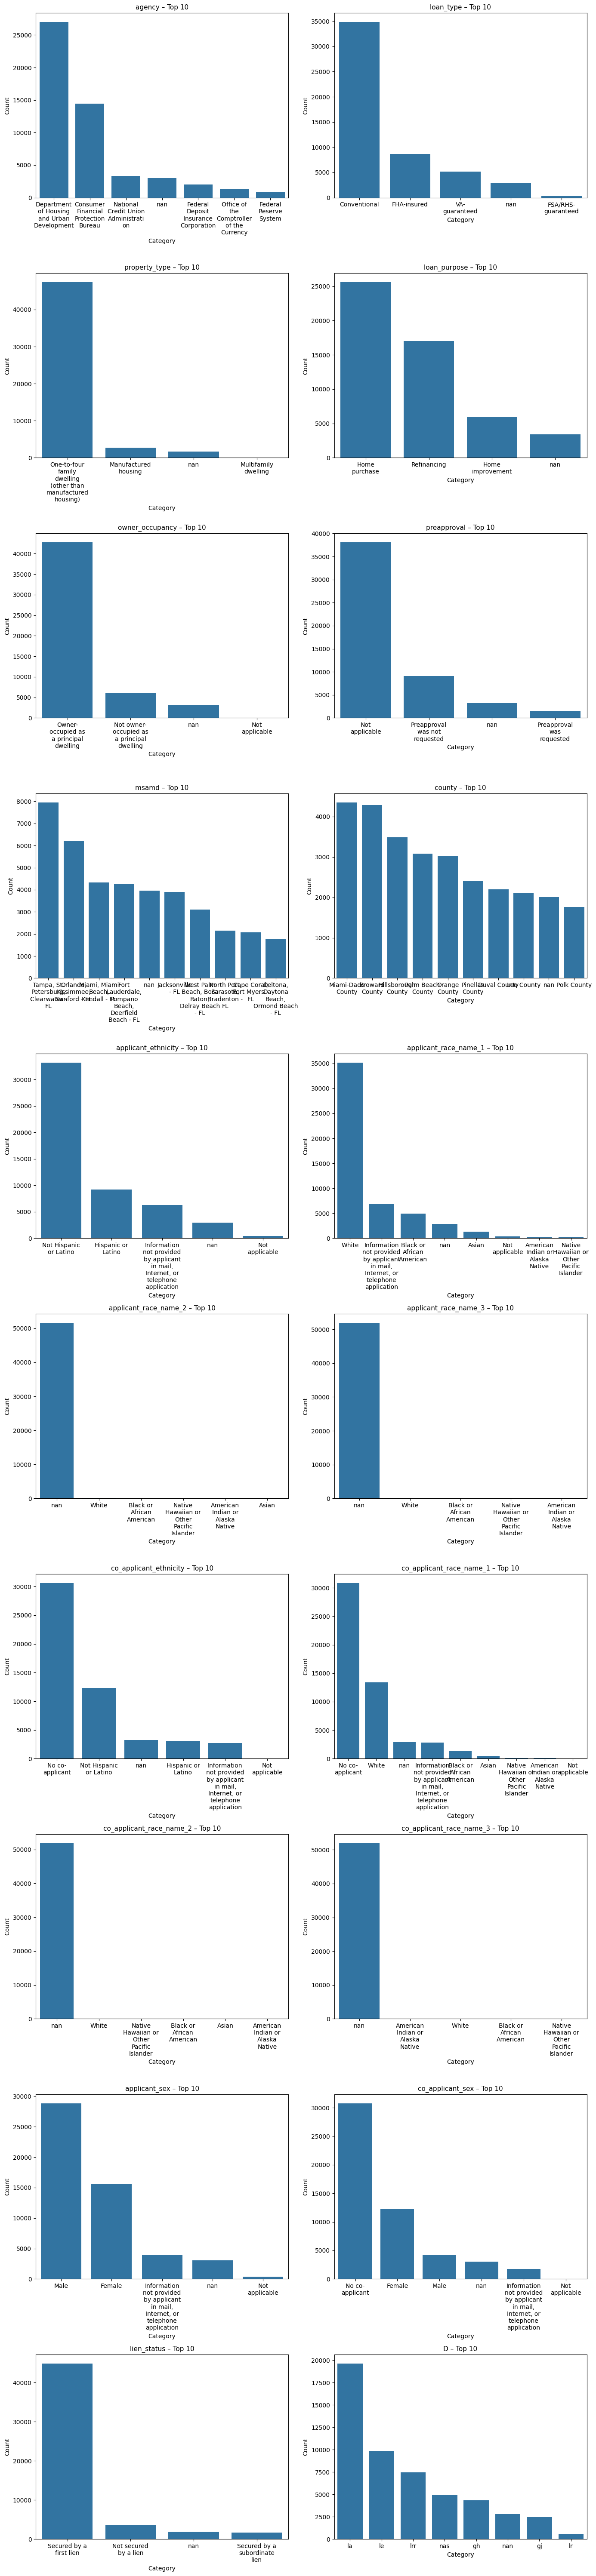

In [ ]:
# create distribution histogram for categorical features
plot_categorical_counts(test, name="Test")

## **2.7 Compare Train-Test Sets**

In [ ]:
# check if all cols exists
def check_unseen_categories(train_df, test_df):
    cat_cols = train_df.select_dtypes(include=['object', 'category', 'bool']).columns
    result = []

    if len(cat_cols) == 0:
        print("⚠️ No categorical columns found in train set.")
        return pd.DataFrame()

    for col in cat_cols:
        if col in test_df.columns:
            train_vals = set(train_df[col].dropna().unique())
            test_vals = set(test_df[col].dropna().unique())
            unseen = test_vals - train_vals

            if unseen:
                result.append({
                    'Column': col,
                    'Unseen categories in test': list(unseen)
                })

    result_df = pd.DataFrame(result)
    if result_df.empty:
        print("✅ No unseen categories in test – all match train.")
    else:
        print("\n🔸 Unseen categories in test:")
        display(result_df)

    return result_df

# check if all cols matches
def compare_train_test_structure(train_df, test_df, label_col='label'):
    print("====== TRAIN vs TEST STRUCTURE CHECK ======\n")

    if label_col in train_df.columns:
        train_df = train_df.drop(columns=[label_col])

    train_cols = set(train_df.columns)
    test_cols = set(test_df.columns)
    diff1 = train_cols - test_cols
    diff2 = test_cols - train_cols

    print("🔸 Columns in train but not in test:", diff1 if diff1 else 0)
    print("🔸 Columns in test but not in train:", diff2 if diff2 else 0)

    if list(train_df.columns) != list(test_df.columns):
        print("\n🔸 Warning: Column order differs between train and test.")

    mismatched_dtypes = {
        col: (train_df[col].dtype, test_df[col].dtype)
        for col in train_cols & test_cols
        if train_df[col].dtype != test_df[col].dtype
    }

    if mismatched_dtypes:
        print("\n🔸 Columns with mismatched dtypes:")
        for col, dtypes in mismatched_dtypes.items():
            print(f"    {col}: train={dtypes[0]}, test={dtypes[1]}")
    else:
        print("\n✅ All dtypes match.")

    test_missing = test_df.isnull().sum()
    if test_missing.sum() > 0:
        print("\n🔸 Missing values in test:")
        print(test_missing[test_missing > 0])
    else:
        print("\n✅ No missing values in test.")

    check_unseen_categories(train_df, test_df)
    print("\n✅ Structure comparison complete.\n")

compare_train_test_structure(train, test)

====== TRAIN vs TEST STRUCTURE CHECK ======

🔸 Columns in train but not in test: 0
🔸 Columns in test but not in train: 0

✅ All dtypes match.

🔸 Missing values in test:
agency                             3002
loan_type                          2971
property_type                      1683
loan_purpose                       3408
owner_occupancy                    3054
loan_amount                        2483
preapproval                        3227
msamd                              3968
county                             2010
county_code                        1899
census_tract_number                2587
applicant_ethnicity                2921
applicant_race_name_1              2871
applicant_race_name_2             51661
applicant_race_name_3             51975
co_applicant_ethnicity             3225
co_applicant_race_name_1           2929
co_applicant_race_name_2          51920
co_applicant_race_name_3          51994
applicant_sex                      3090
co_applicant_sex               

# **PART 3: EXPLORATORY DATA ANALYSIS (EDA)**

## **3.1 Fixed Features Classification**

### **3.1.1 Automatic Categorical Classification**

In [ ]:
# Identify categorical columns in a dataframe based on data type and cardinality
def get_categorical_columns(df, threshold=15):
    cat_cols = []
    # Iterate over all columns in the dataframe
    for col in df.columns:
        # If the column is explicitly categorical (object, bool, or category), add to list
        if df[col].dtype in ['object', 'bool', 'category']:
            cat_cols.append(col)
        # If the column is numeric but has a limited number of unique values, treat it as categorical
        elif pd.api.types.is_numeric_dtype(df[col]):
            if df[col].nunique() <= threshold:
                cat_cols.append(col)
    return cat_cols

cat_cols = get_categorical_columns(train)

print("Categorical columns:")
for col in cat_cols:
    print("-", col)

Categorical columns:
- agency
- loan_type
- property_type
- loan_purpose
- owner_occupancy
- preapproval
- msamd
- county
- applicant_ethnicity
- applicant_race_name_1
- applicant_race_name_2
- applicant_race_name_3
- co_applicant_ethnicity
- co_applicant_race_name_1
- co_applicant_race_name_2
- co_applicant_race_name_3
- applicant_sex
- co_applicant_sex
- lien_status
- D
- label


### **3.1.2 Automatic Numeric Classification**

In [ ]:
# Identify numerical columns by excluding known categorical columns
def get_numerical_columns(df, cat_cols):
    return [col for col in df.columns if col not in cat_cols]

num_cols = get_numerical_columns(train, cat_cols)

print("Numerical columns:")
for col in num_cols:
    print("-", col)

Numerical columns:
- ID
- loan_amount
- county_code
- census_tract_number
- applicant_income
- population
- minority_population
- hud_median_family_income
- tract_to_msamd_income
- number_of_owner_occupied_units
- A
- B
- C


### **3.1.3 Manual Features Classification**

To ensure that the automatic column classification is accurate, I manually reviewed each column. I examined the number of unique values, the value range, and the general behavior of the values — for example, whether the numbers are always rounded, include negative values, or show large jumps. I also reviewed each feature's distribution. Based on these observations, I will now manually correct columns that were classified as categorical but are more appropriately treated as numerical.

In [ ]:
# manual features classification fixation
fix_to_categorical = ['county_code', 'census_tract_number']
for col in fix_to_categorical:
    if col in train.columns:
        train[col] = train[col].astype('category')
        print(f"{col} converted to category.")
    else:
        print(f"Column {col} not found in dataframe.")

# add new classification to features class lists
for col in fix_to_categorical:
    if col in num_cols:
        num_cols.remove(col)
    if col not in cat_cols:
        cat_cols.append(col)

county_code converted to category.
census_tract_number converted to category.


### **3.1.4 Verify Global Definition of cat_cols & num_cols**

In [ ]:
# remove label from cat_cols and validate cols names
cat_cols = [col for col in cat_cols if col != 'label']
cat_cols

['agency',
 'loan_type',
 'property_type',
 'loan_purpose',
 'owner_occupancy',
 'preapproval',
 'msamd',
 'county',
 'applicant_ethnicity',
 'applicant_race_name_1',
 'applicant_race_name_2',
 'applicant_race_name_3',
 'co_applicant_ethnicity',
 'co_applicant_race_name_1',
 'co_applicant_race_name_2',
 'co_applicant_race_name_3',
 'applicant_sex',
 'co_applicant_sex',
 'lien_status',
 'D',
 'county_code',
 'census_tract_number']

In [ ]:
# remove ID from num_cols and validate cols names
num_cols = [col for col in num_cols if col != 'ID']
num_cols

['loan_amount',
 'applicant_income',
 'population',
 'minority_population',
 'hud_median_family_income',
 'tract_to_msamd_income',
 'number_of_owner_occupied_units',
 'A',
 'B',
 'C']

## **3.2 Univariate Analysis**

### **3.2.1 Label Balance**

Label balance analysis helps identify whether the label is distributed evenly across classes. An imbalanced dataset can lead to biased models that perform well on the dominant class but poorly on the minority class. This can result in misleading accuracy scores and poor generalization. By evaluating label balance early, we can determine whether techniques such as resampling, class weighting, or synthetic data generation are necessary to ensure fair and effective model training.

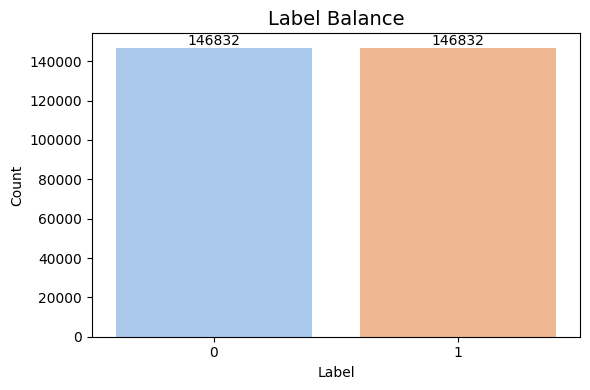

In [ ]:
# show how many appereances of each label exists
def plot_label_balance(df, label_col='label'):
    plt.figure(figsize=(6, 4))
    ax = sns.countplot(x=label_col, data=df, palette="pastel")

    plt.title("Label Balance", fontsize=14)
    plt.xlabel("Label")
    plt.ylabel("Count")

    for p in ax.patches:
        count = int(p.get_height())
        ax.annotate(count, (p.get_x() + p.get_width() / 2., count),
                    ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.show()

plot_label_balance(train, label_col='label')

### **3.2.2 Histograms**

======= DATA – NUMERIC DISTRIBUTIONS =======


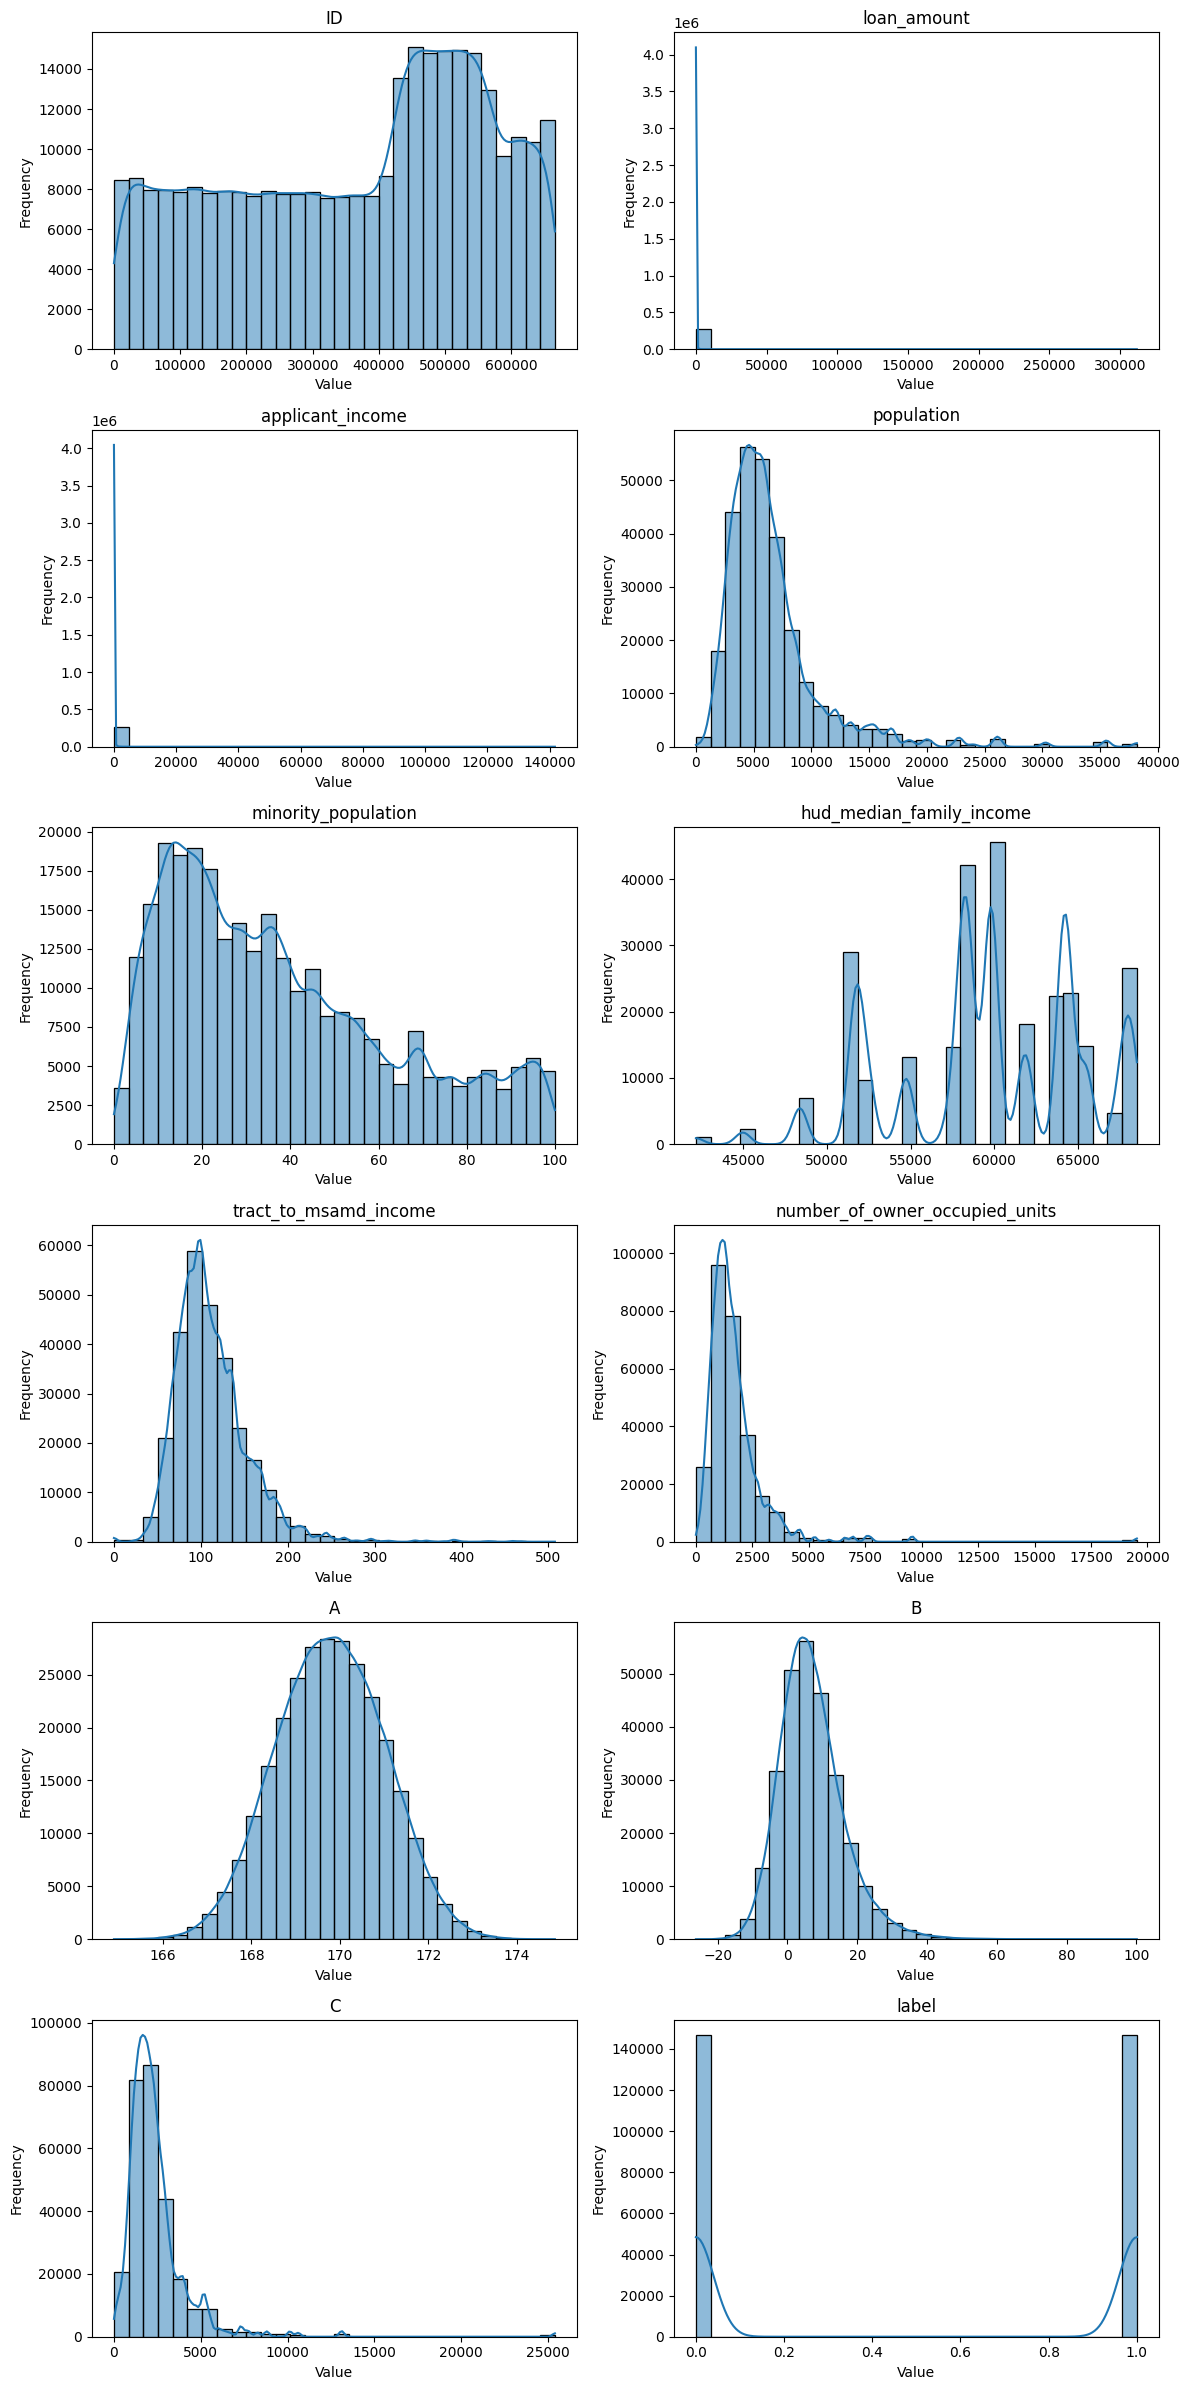

In [ ]:
# show numeric cols distribution
plot_numeric_distributions(train)

💡**loan_amount** | The distribution is highly skewed to the right, with most loans concentrated in the lower range and a long tail of higher values. This indicates potential outliers and the need for transformation or outlier handling in preprocessing.

---


💡**applicant_income** | extremely right-skewed, with most values concentrated at the lower end of the range and a very long tail of higher incomes. This suggests the presence of extreme outliers and a strong imbalance in income distribution.


---


💡**population** | appears to follow a right-skewed distribution but with a more regular shape than applicant_income. Most values fall between 2,000 and 10,000, with some high-population outliers. This feature might benefit from standardization or transformation depending on the model used.


---


✅**minority_population** | represents a percentage (0–100) and is slightly left-skewed. Most values cluster between 10% and 40%, but the distribution is fairly spread out across the full range. The variable appears continuous and does not need transformation unless a model is sensitive to skewness.


---


💡**hud_median_family_income** | strange, bumpy distribution with distinct peaks, likely due to rounding or group-based income bands. The distribution is right-skewed and not smooth, suggesting it may benefit from normalization or binning depending on model choice.


---


💡**tract_to_msamd_income** | shows a right-skewed distribution centered around 100, which is likely a ratio. The long tail suggests the need for normalization or transformation before modeling.


---


💡**number_of_owner_occupied_units** | heavily right-skewed. Most values fall under 3,000, but the tail extends far beyond that. Since this is a count variable, it might benefit from log transformation to reduce skewness and improve model performance.


---


✅**A** | a near-perfect normal distribution centered around 170, with a narrow range (~165–175). This suggests it's a well-behaved numeric feature, potentially a standardized physical measurement. No transformation is needed.


---


✅**B** | approximately normal, centered around 5–10, but with a long positive tail. Range includes negative values, indicating it’s an continuous numeric feature. Suitable for modeling as-is, though minor right skew could be adjusted if needed.


---


💡**C** | highly right-skewed, with most values concentrated between 0–5000 and a long tail extending to ~25,000. Despite all values being decimal with .0, the continuous spread and variability suggest it's a numeric feature, not categorical. It might benefit from log transformation to normalize the distribution for modeling.

### **3.2.3 Boxplots - Numeric Cols Distribution**


======= DATA – NUMERIC BOXPLOTS =======


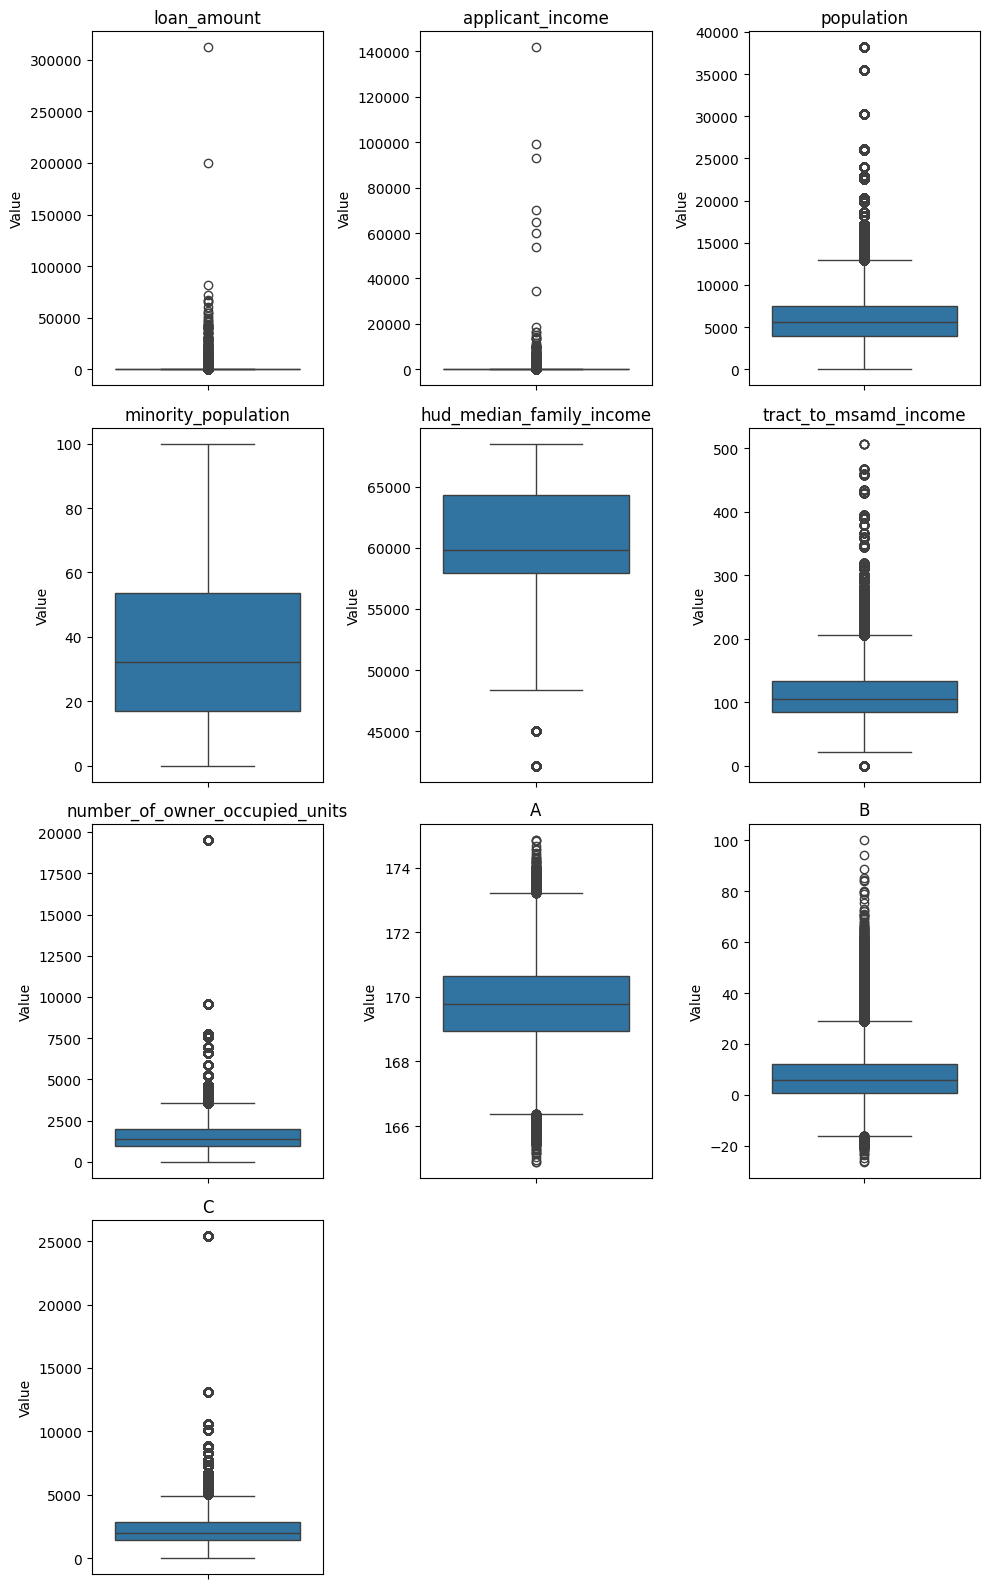

In [ ]:
# show numeric cols distribution in boxplots
def plot_numeric_boxplots(df, name="Data"):
    num_plots = len(num_cols)

    print(f"======= {name.upper()} – NUMERIC BOXPLOTS =======")

    ncols = 3
    nrows = math.ceil(num_plots / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(10, 4 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.boxplot(y=df[col], ax=axes[i])
        axes[i].set_title(col)
        axes[i].set_ylabel("Value")
        axes[i].set_xlabel("")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_numeric_boxplots(train)

💡**loan_amount** | Most loan amounts are concentrated in the lower range, with extremely high outliers reaching several hundred thousand. The distribution is strongly right-skewed. This suggests a need for log transformation, robust scaling, or outlier handling.

---

💡**applicant_income** | The vast majority of values are low, but a few very high-income values create extreme outliers. The distribution is highly skewed, and we should consider transformation or outlier removal. It might also be useful to verify the validity of the extreme values—they could be errors or true exceptions.

---

💡**population** | The distribution shows a high concentration around the median, but with many high-end outliers, reaching values well above 30,000. This feature is right-skewed. We might consider transformations, scaling methods robust to outliers, or further investigating those extreme values.

---

✅ **minority_population** | This feature has a relatively symmetric distribution without visible outliers. The data appears well-behaved and normally distributed. No preprocessing needed here in terms of outlier handling.

---

💡**hud_median_family_income** | The values are moderately skewed, with a few low-end outliers. The variable seems fairly stable overall. While the outliers are not extreme, we may still consider winsorizing or keeping them if they reflect realistic socioeconomic variation.

---

💡**tract_to_msamd_income** | The distribution is right-skewed with a substantial number of high outliers, some going beyond 500. These outliers might represent neighborhoods with extremely high relative income.

---

💡**number_of_owner_occupied_units** | The feature is heavily skewed with many extreme outliers. This may reflect a few very large areas with many units. We may want to log-transform or cap outliers depending on model sensitivity.

---

✅ **A** | The distribution appears to be symmetric and normal, but includes a fair amount of mild outliers on both ends. These are not extreme and may be safe to leave as is. No immediate action is needed unless a specific model is highly sensitive

---

💡**B** | The distribution is centered around zero with a large number of outliers on both sides, especially positive. This likely reflects a skewed distribution. Depending on model sensitivity, will consider transformation, though the symmetric shape suggests standardization might also help.

---

💡**C** | The feature shows strong right skewness with numerous extreme outliers, including some above 25,000. These may significantly affect model performance. Will consider using log transformation or outlier handling strategies.

---


The boxplots largely confirm the patterns observed in the histograms. Variables such as applicant_income, loan_amount, population, tract_to_msamd_income, and C display strong right-skewed distributions and numerous outliers in both visualizations, indicating heavy-tailed behavior. In contrast, A shows a nearly perfect normal distribution with minimal spread and no significant outliers, as reflected consistently in both plots. minority_population demonstrates a wide, fairly uniform distribution with moderate spread, while label, being binary, appears as a flat distribution in both plots. A slight discrepancy was noted in hud_median_family_income, where the histogram showed irregular clustering (possibly due to rounding or preprocessing), while the boxplot suggests a relatively symmetric distribution with few outliers. Overall, the boxplots provide additional insight into spread and outliers, reinforcing and complementing the findings from the histograms.

### **3.2.4 Countplots - Categoric Cols Distribution**

======= TRAIN CATEGORICAL COUNTS =======


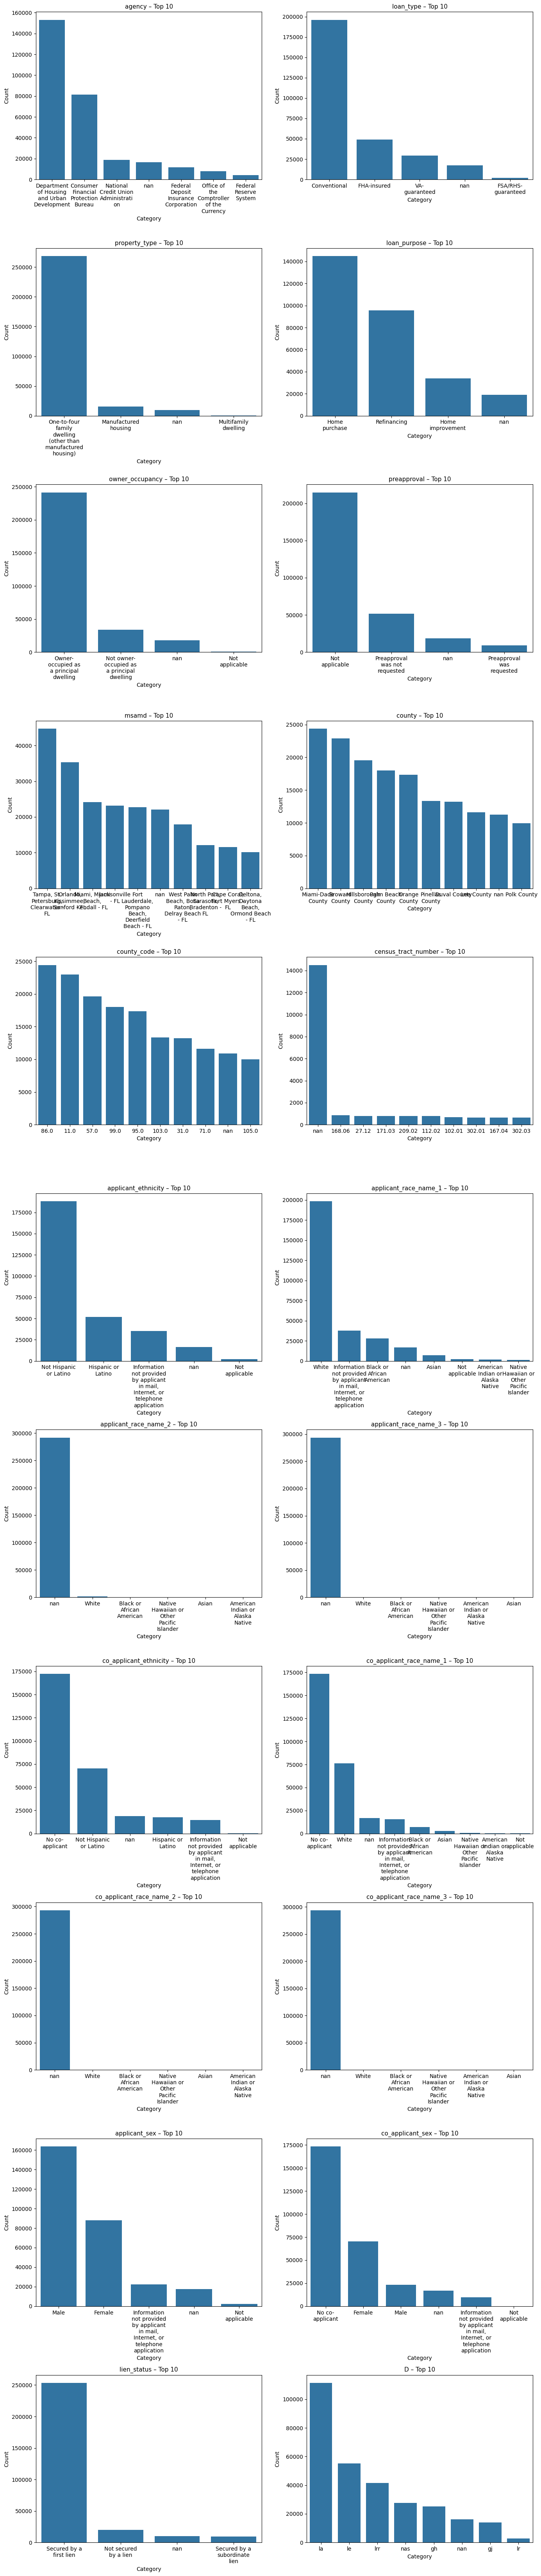

In [ ]:
# create categorical cols distribution histogram
plot_categorical_counts(train, name="Train")

✅**agency** | represents the reporting agency. It includes a small number of categories such as "Consumer Financial Protection Bureau" or "Office of the Comptroller of the Currency".
Conclusion: Low cardinality, meaningful categorical feature — should be kept.

---

✅**loan_type** | Refers to the type of loan. Categories are distinct and limited in number.
Conclusion: Important categorical feature with clear financial meaning — should be kept.

---

✅**property_type** | describes the property being financed, such as "One-to-four-family" or "Multifamily".
Conclusion: Low cardinality and interpretable — recommended to keep.

---

✅**loan_purpose** | Captures the purpose of the loan, such as "Home purchase", "Home improvement", or "Refinancing".
Conclusion: Key categorical variable — should be retained.

---

✅**owner_occupancy** | Indicates whether the property is owner-occupied or not.
Conclusion: Binary feature — clear and relevant, should be kept.

---

✅**preapproval** | Shows whether a loan request was preapproved. Contains only a few values.
Conclusion: Simple and potentially predictive — should be kept.

---

💡**census_tract_number** | has a very high proportion of missing values, and the remaining values are extremely sparse.
Conclusion: Due to missingness and fragmentation, it is unlikely to be useful — consider dropping.

---

✅**applicant_ethnicity** | Includes clear categories like "Hispanic or Latino", "Not Hispanic or Latino", and "Information not provided".
Conclusion: Important demographic feature — should be kept.

---

✂️**applicant_race_name_2, applicant_race_name_3** | mostly missing, offering little additional insight.
Conclusion: Sparse and low-value — should be removed.

---

💡**co_applicant_ethnicity** | Majority of entries are "No co-applicant", followed by "Not Hispanic or Latino".
Conclusion: Can be retained as-is or simplified into "Has co-applicant" vs "No co-applicant".

---

💡**co_applicant_race_name_1** | Most entries are "No co-applicant" or "White", with other races much less frequent.
Conclusion: Relevant if co-applicants are considered; could be simplified for modeling.

---

✂️**co_applicant_race_name_2, co_applicant_race_name_3** | Almost entirely missing or sparse.
Conclusion: Should be dropped.

---

✅**applicant_sex** | Well-distributed between "Male" and "Female", with some missing or unspecified.
Conclusion: Informative demographic feature — retain.

---

💡**co_applicant_sex** | Most entries are "No co-applicant", followed by "Female" and "Male".
Conclusion: Can be used directly or converted to "Has co-applicant" binary flag.

---

✅**lien_status** | Most loans are "Secured by a first lien", with few "Not secured" or "Subordinate lien".
Conclusion: Important financial status — should be kept.

---

💡**D** | Appears to contain short codes (e.g., la, le, lrr) with a long tail of values.
Conclusion: Consider grouping rare values as "Other" to reduce cardinality.

### **3.2.5 Outliers**

In [ ]:
# discover numeric continuous features
def get_continuous_features(df, unique_threshold=15):
    continuous_cols = []

    for col in num_cols:
        unique_vals = df[col].dropna().unique()
        has_decimals = any(val % 1 != 0 for val in unique_vals)
        if has_decimals or len(unique_vals) > unique_threshold:
            continuous_cols.append(col)

    return continuous_cols

continuous_features = get_continuous_features(train)
print("Continuous numeric features:")
for col in continuous_features:
    print(f"• {col}")

if continuous_features == num_cols:
    print("\n All numeric features are continuous.")
else:
    print("\n NOT all numeric features are continuous.")

Continuous numeric features:
• loan_amount
• applicant_income
• population
• minority_population
• hud_median_family_income
• tract_to_msamd_income
• number_of_owner_occupied_units
• A
• B
• C

 All numeric features are continuous.


In [ ]:
# check if features distributes normaly to decide IQR Vs. Z-score
columns_to_test = ['population', 'tract_to_msamd_income', 'number_of_owner_occupied_units', 'A', 'B', 'C']

for col in columns_to_test:
    try:
        stat, p = shapiro(train[col].dropna())
        print(f'{col}: p-value = {p:.4f} {"✓ Normal" if p > 0.05 else "✗ Not normal"}')
    except Exception as e:
        print(f'{col}: Error - {e}')

population: p-value = 0.0000 ✗ Not normal
tract_to_msamd_income: p-value = 0.0000 ✗ Not normal
number_of_owner_occupied_units: p-value = 0.0000 ✗ Not normal
A: p-value = 0.0000 ✗ Not normal
B: p-value = 0.0000 ✗ Not normal
C: p-value = 0.0000 ✗ Not normal


In [ ]:
# find outliers using IQR
Q1 = train[num_cols].quantile(0.25)
Q3 = train[num_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = ((train[num_cols] < lower_bound) | (train[num_cols] > upper_bound))

outliers_iqr_count = outliers_iqr.sum().sort_values(ascending=False)

print("Number of outliers per feature (IQR method):")
print(outliers_iqr_count)

print("\nPercentage of outliers and their effect on mean and std:")

for col in outliers_iqr_count.index:
    outlier_mask = outliers_iqr[col]
    percent = 100 * outlier_mask.sum() / len(train)

    mean_full = train[col].mean()
    std_full = train[col].std()
    mean_clean = train.loc[~outlier_mask, col].mean()
    std_clean = train.loc[~outlier_mask, col].std()

    print(f"▫️{col}: {percent:.2f}% outliers | Mean full={mean_full:.2f}, clean={mean_clean:.2f} | Std full={std_full:.2f}, clean={std_clean:.2f}")


Number of outliers per feature (IQR method):
population                        19932
applicant_income                  19548
C                                 17993
number_of_owner_occupied_units    14121
loan_amount                       10991
tract_to_msamd_income              7717
B                                  6702
hud_median_family_income           3395
A                                   905
minority_population                   0
dtype: int64

Percentage of outliers and their effect on mean and std:
▫️population: 6.79% outliers | Mean full=6537.52, clean=5609.80 | Std full=4403.11, clean=2391.47
▫️applicant_income: 6.66% outliers | Mean full=101.40, clean=72.95 | Std full=495.57, clean=41.06
▫️C: 6.13% outliers | Mean full=2393.06, clean=2061.22 | Std full=1824.96, clean=975.67
▫️number_of_owner_occupied_units: 4.81% outliers | Mean full=1682.50, clean=1472.42 | Std full=1333.22, clean=709.76
▫️loan_amount: 3.74% outliers | Mean full=210.96, clean=170.09 | Std full=974.28, c

❗️**population** | A high proportion of outliers, with a significant impact on the mean and standard deviation.

---

❗️**applicant_income** | A high proportion of outliers, with a significant impact on the mean and standard deviation.

---

❗️**C** | A high proportion of outliers, with a significant impact on the mean and standard deviation.

---

❗️**number_of_owner_occupied_units** | A high proportion of outliers, with a significant impact on the mean and standard deviation.

---

❗️**loan_amount** | A high proportion of outliers, with a significant impact on the mean and standard deviation.

---

❗️**tract_to_msamd_income** | A high proportion of outliers, with a significant impact on the mean and standard deviation.

---

❗️**B** | A high proportion of outliers, with a significant impact on the mean and standard deviation.

---

🆗 **hud_median_family_income** | A small percentage of outliers with minimal impact on both the mean and the standard deviation.

---

🆗 **A** | A small percentage of outliers with no impact on the mean and a negligible effect on the std.

---

🆗 **minority_population** | No outliers.

### **3.2.6 Anomalies**

In [ ]:
# use Isolatin Forest method to find anomalies in train data (using random distribution)
iso = IsolationForest(contamination=0.01, random_state=42)
train['anomaly'] = iso.fit_predict(train[num_cols])
anomalies = train[train['anomaly'] == -1]

print(f"Number of anomalies detected: {anomalies.shape[0]}")

anomaly_ratio = len(anomalies) / len(train) * 100
print(f"Percentage of anomalies: {anomaly_ratio:.2f}%")

Number of anomalies detected: 2937
Percentage of anomalies: 1.00%


✅ An anomaly rate of 1% is considered relatively low, and therefore it's generally reasonable to leave these anomalies as is—provided they do not significantly distort the distribution of the features or affect model performance.

In [ ]:
# use LOF method to find anomalies in train data (by density)
lof = LocalOutlierFactor(n_neighbors=20)
lof_data = train[num_cols].dropna()
train_cleaned = train.loc[lof_data.index].copy()
train_cleaned['lof_score'] = lof.fit_predict(lof_data)
anomalies_lof = train_cleaned[train_cleaned['lof_score'] == -1]

print(f"Number of anomalies detected by LOF: {len(anomalies_lof)}")

percentage = len(anomalies_lof) / len(train_cleaned) * 100
print(f"Percentage of anomalies: {percentage:.2f}%")

Number of anomalies detected by LOF: 15294
Percentage of anomalies: 9.27%


✅ An anomaly rate of 4.5% is relatively low, so it's generally acceptable to keep these anomalies as-is, unless they significantly distort feature distributions or model performance.

In [ ]:
# find anomalies in categorical features by percentae of appereances
for col in cat_cols:
    counts = train[col].value_counts(normalize=True)
    rare = counts[counts < 0.005]
    if not rare.empty:
        print(f"💠Rare categories in '{col}':")
        if len(rare) > 15:
            print(f"  - {len(rare)} rare categories in this feature❗️")
        else:
            for category, proportion in rare.items():
                print(f"  - {category}: {proportion:.4%}")
        print()

💠Rare categories in 'property_type':
  - Multifamily dwelling: 0.1600%

💠Rare categories in 'owner_occupancy':
  - Not applicable: 0.1823%

💠Rare categories in 'msamd':
  - Sebring - FL: 0.4322%

💠Rare categories in 'county':
  - 30 rare categories in this feature❗️

💠Rare categories in 'applicant_race_name_1':
  - Native Hawaiian or Other Pacific Islander: 0.4059%

💠Rare categories in 'co_applicant_ethnicity':
  - Not applicable: 0.0531%

💠Rare categories in 'co_applicant_race_name_1':
  - Native Hawaiian or Other Pacific Islander: 0.2114%
  - American Indian or Alaska Native: 0.1901%
  - Not applicable: 0.0430%

💠Rare categories in 'co_applicant_sex':
  - Not applicable: 0.0419%

💠Rare categories in 'county_code':
  - 30 rare categories in this feature❗️

💠Rare categories in 'census_tract_number':
  - 2972 rare categories in this feature❗️



## **3.3 Bivariate Analysis**

### **3.3.1 Barplots (Cateoric Vs. Label)**

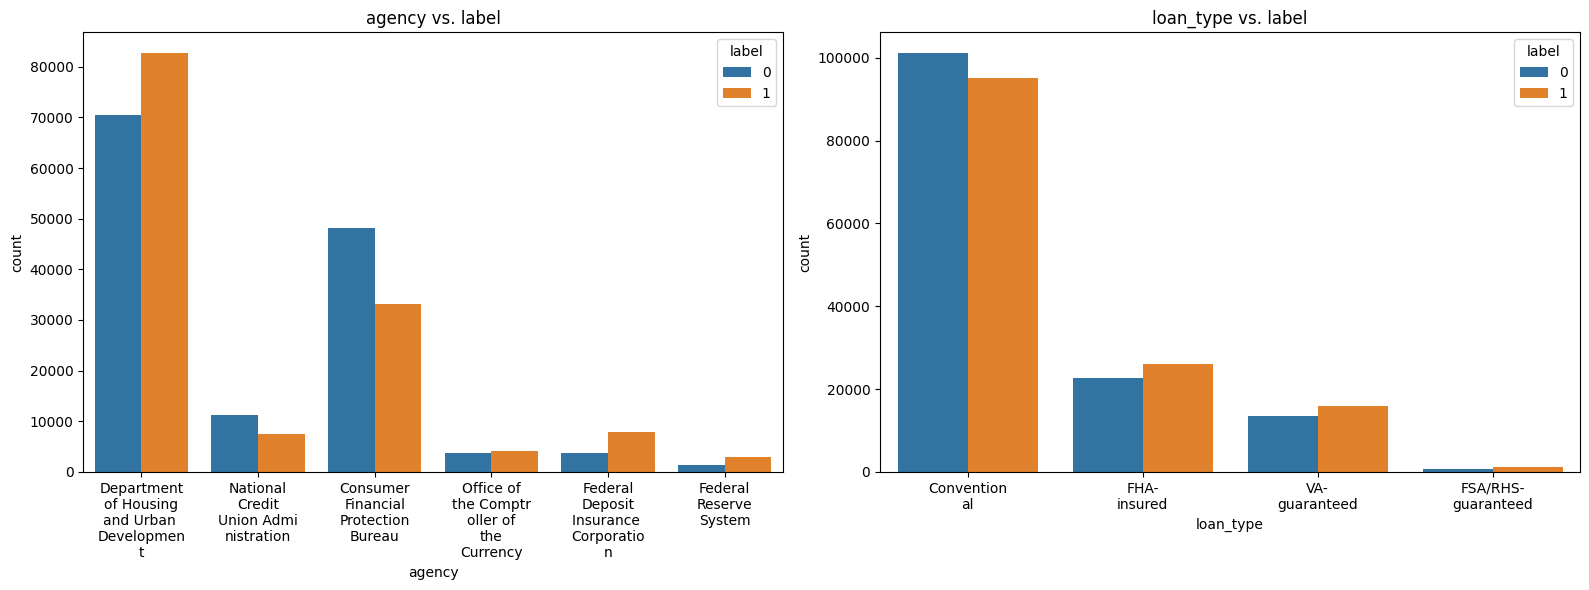

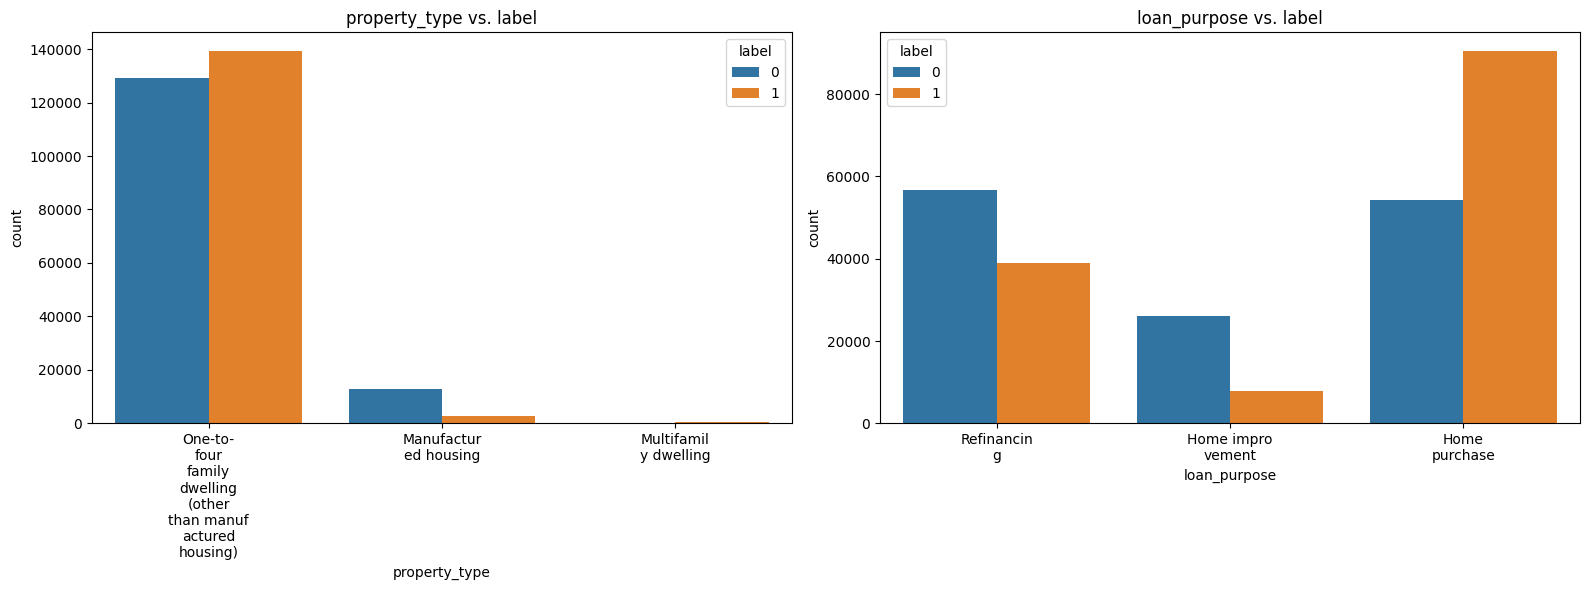

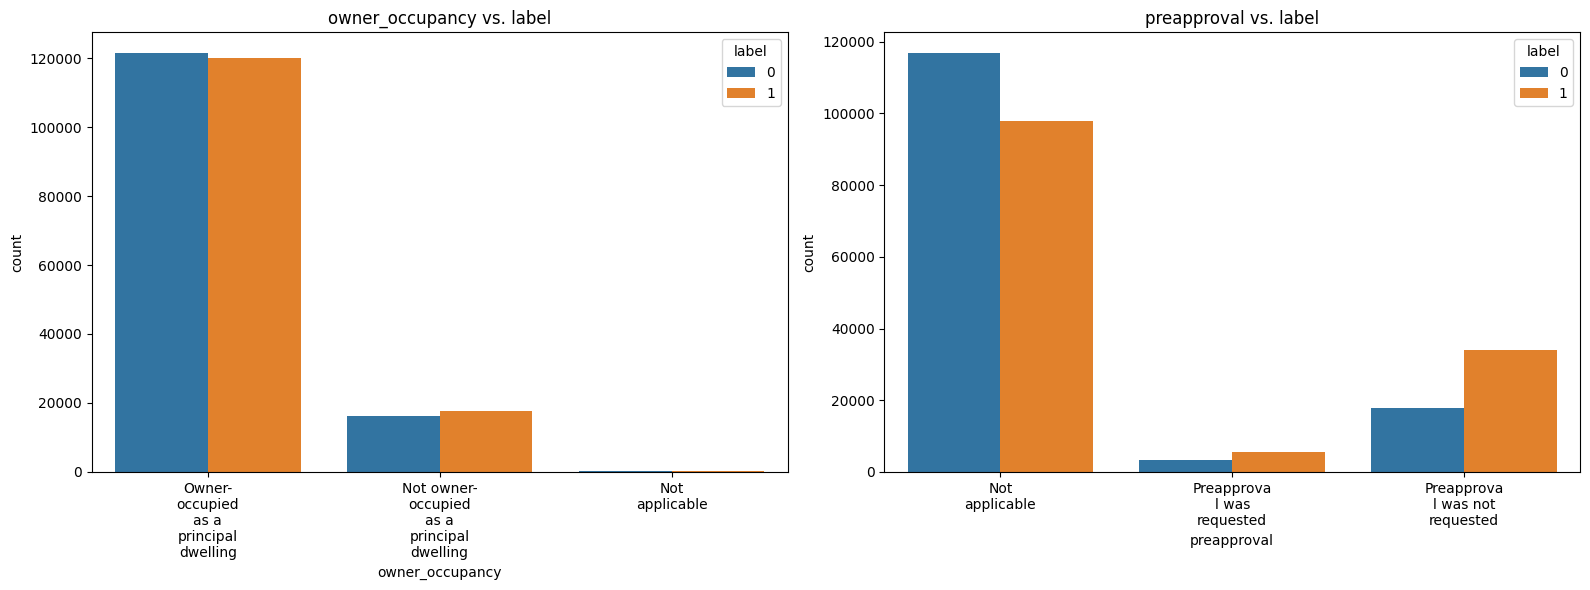

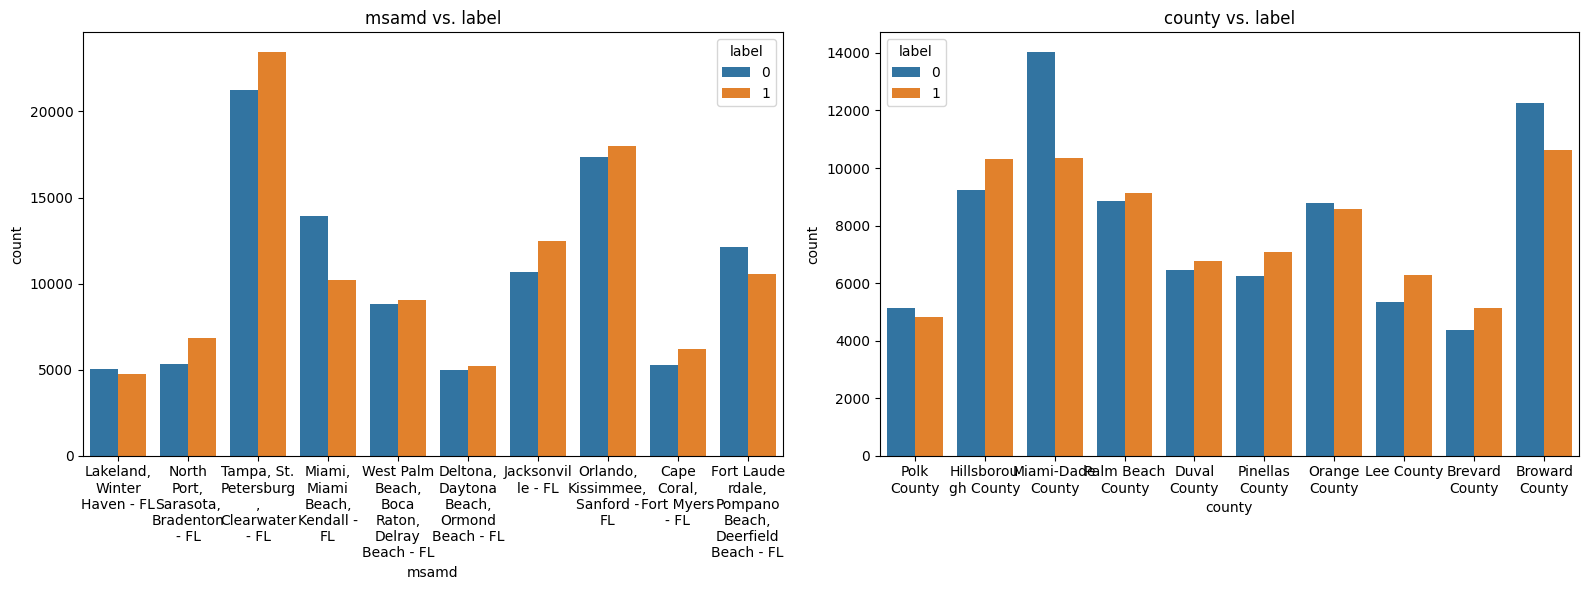

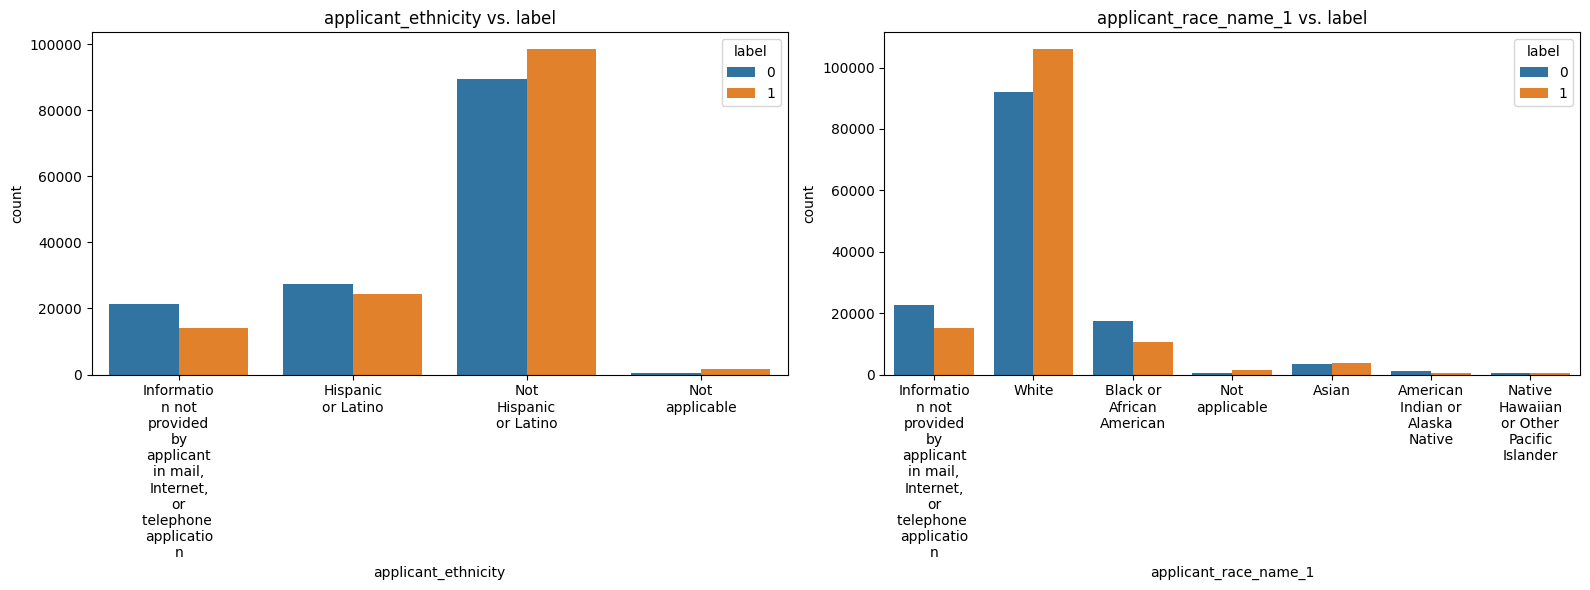

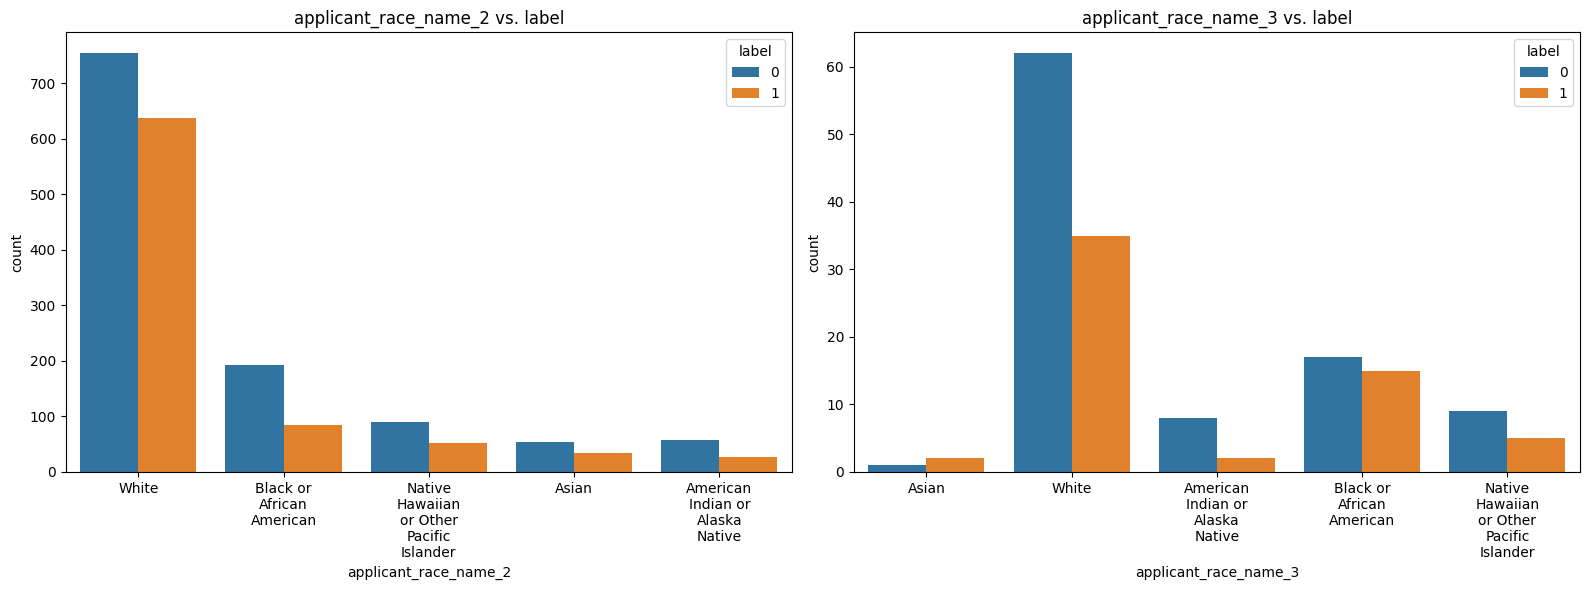

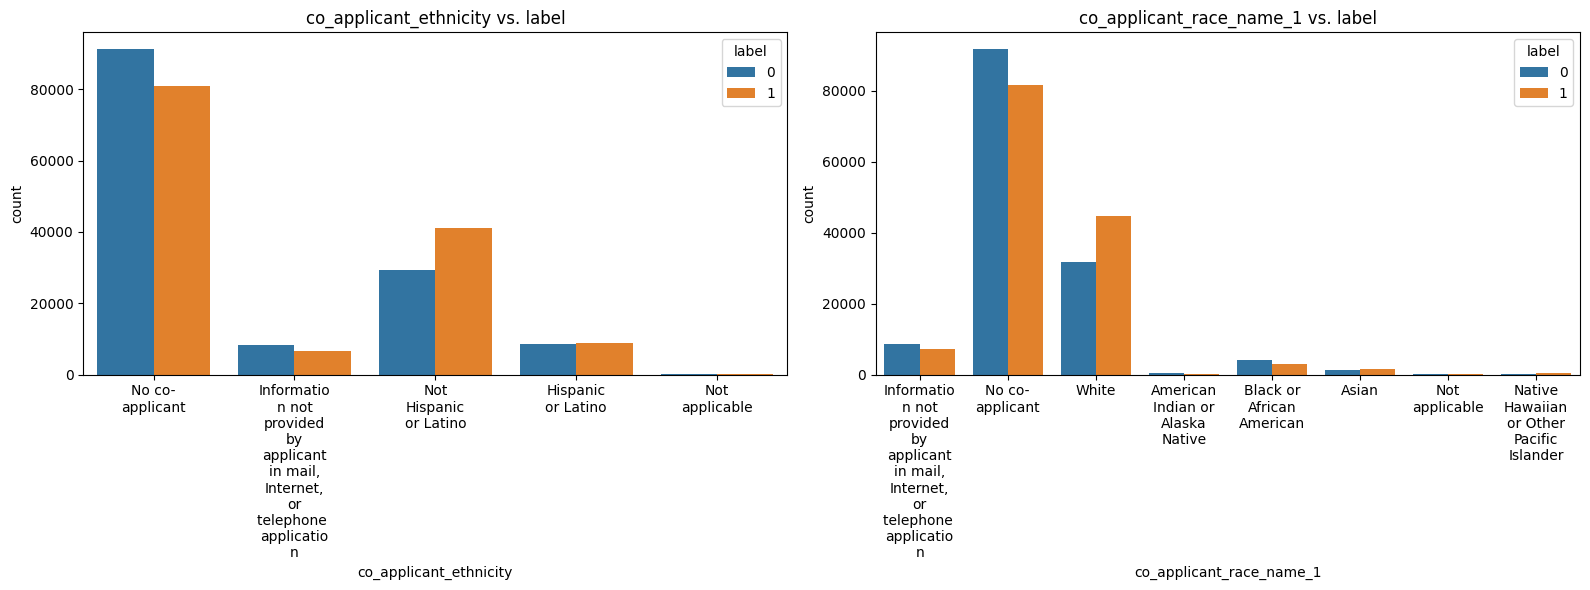

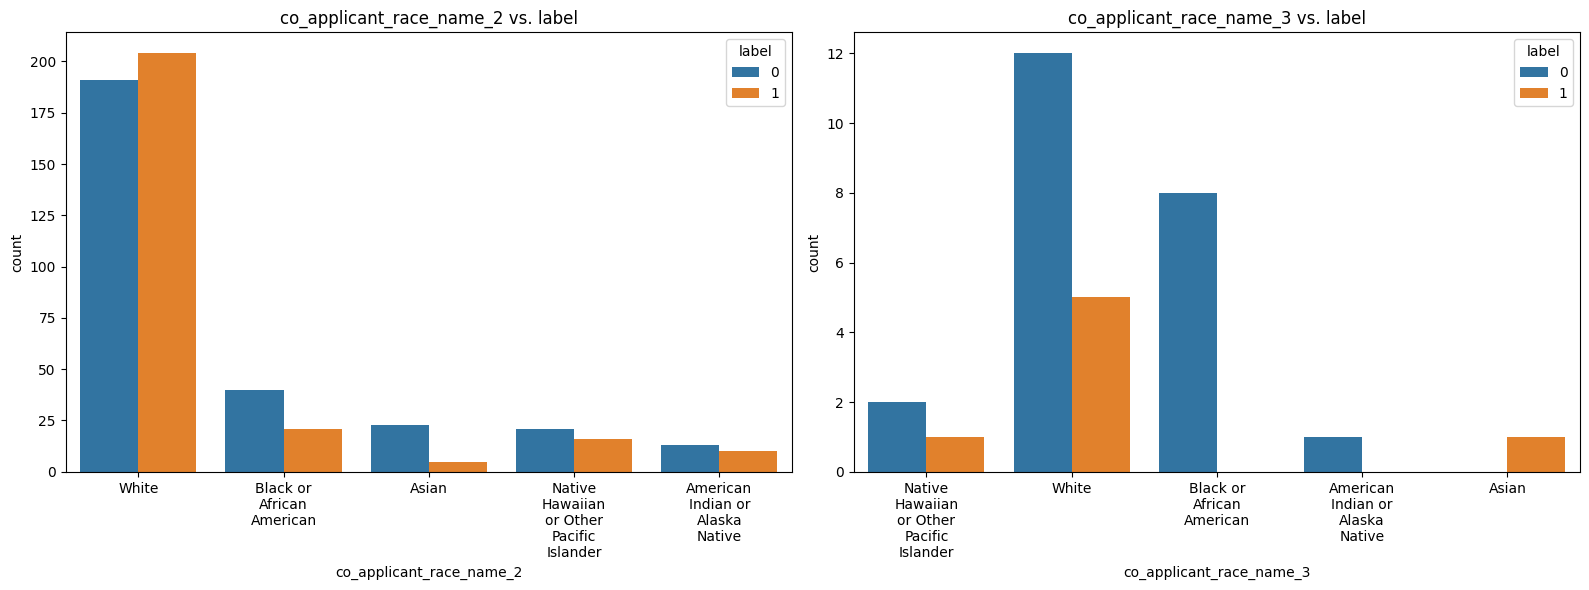

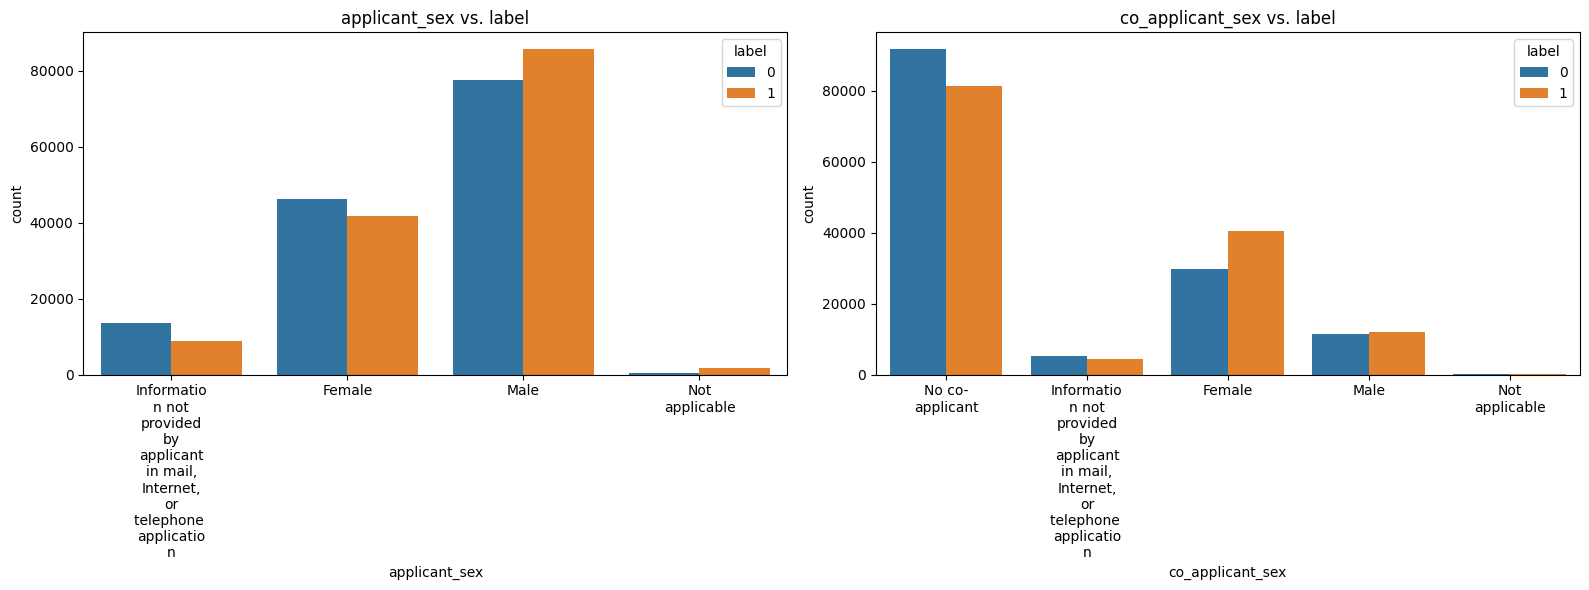

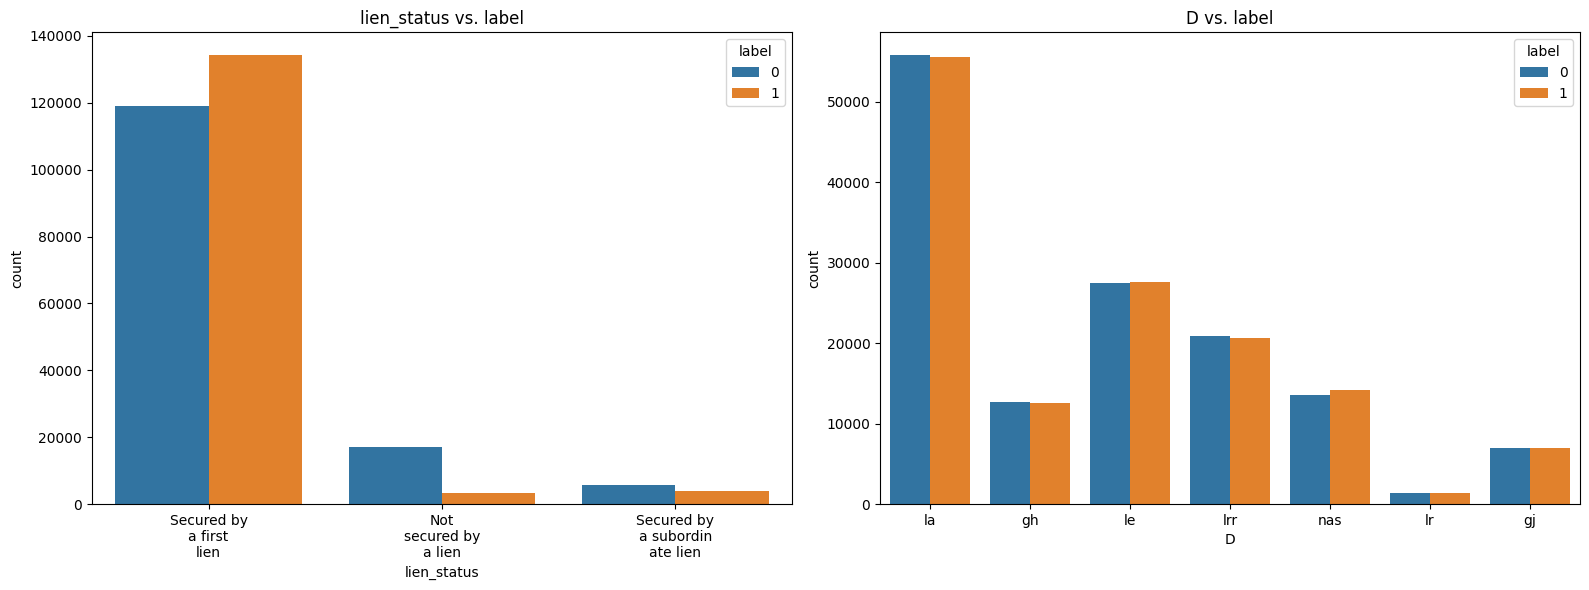

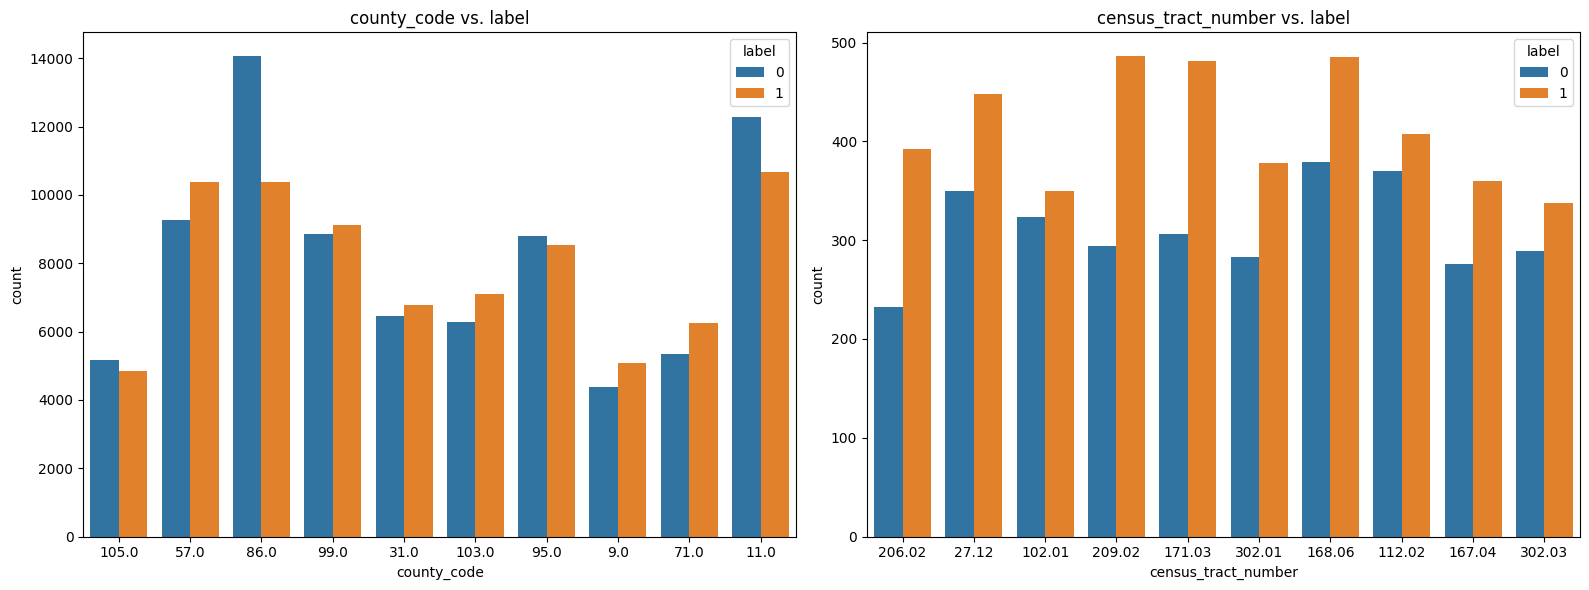

In [ ]:
# show relationship between categorical features and the label
top_k = 10

for i in range(0, len(cat_cols), 2):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for j in range(2):
        if i + j < len(cat_cols):
            col = cat_cols[i + j]
            top_values = train[col].value_counts().nlargest(top_k).index
            subset = train[train[col].isin(top_values)].copy()

            if subset.empty:
                fig.delaxes(axes[j])
                continue

            subset[col] = subset[col].astype(str).apply(lambda x: '\n'.join(textwrap.wrap(x, 10)))
            sns.countplot(data=subset, x=col, hue='label', ax=axes[j])
            axes[j].set_title(f"{col} vs. label")
            axes[j].tick_params(axis='x', rotation=0)
        else:
            fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

####results analysis (🟠 = tend to approve, 🔵 = tend to unapprove, 🔘 = balanced):

---



###**agency**

🟠Department of Housing and Urban Development – Large volume with a higher approval rate.

🔵Consumer Financial Protection Bureau – Medium-high volume with noticeably higher approvals.

🔵National Credit Union Administration and Federal Reserve System – Very low volume but mostly approved.

---

###**loan_type**

🔘Conventional – The majority of applications, with almost balanced approval/rejection ratio.

🟠FHA-insured and VA-guaranteed – Slightly higher approval rates.

🟠FSA/RHS-guaranteed – Rare, but mostly approved.

---

###**property_type**

🟠One-to-four family dwelling – Dominant category, slightly favoring approvals.

🔵Manufactured housing – Rare, but mostly unapproved.

🔘Multifamily dwelling – Very rare.

---

###**loan_purpose**

🟠Home purchase – Strong approval dominance.

🔵Refinancing – Tends to be rejected more often.

🔵Home improvement – Mostly rejected.


---

###**owner_occupancy**

🔘Owner-occupied – Most common; balanced outcome.

🔘Not owner-occupied – Moderate volume; almost balanced.

---

###**preapproval**

🔵Not applicable – Most cases; higher unapproval rate.

🟠Preapproval not requested – favors approvals.

🟠Preapproval requested – favors approvals.

---

###**msamd**

Regional variation observed – e.g., Tampa with more approvals, Miami and Orlando show less clear trends.

---

###**county**

Differences exist by county – e.g., Miami-Dade shows higher approval rate, Broward slightly lower.

---

###**applicant_ethnicity**

🟠Not Hispanic or Latino – Majority; more approvals than denials.

🔵Hispanic or Latino – Smaller group; more denials than approvals.

🔵Information not provided – Higher rejection rate.

---

###**applicant_race_name_1**

🟠White – Largest group; more approvals than denials.

🔵Information not provided – Higher rejection rate.
Black or African American – High rejection rate.

---

###**applicant_race_name_2 / 3**

Very rare values; trends are not meaningful due to low volume.

---

###**co_applicant_ethnicity**

🔵No co-applicant – Most frequent; favors approvals.

🔘Hispanic or Latino – balanced.

🟠Not Hispanic or Latino – favors approval.

---

###**co_applicant_race_name_1 / 2 / 3**

Most are either No co-applicant or White.

Other values have low volume, no clear patterns.

---

###**applicant_sex**

🟠Male – Large group; more approvals.

🔵Female – Slightly more denials.

🔵Not provided – Tends to be rejected more often.

---

###**co_applicant_sex**

🔵No co-applicant – Majority; higher approval rate.

🟠Female – Slightly more rejections.

🔘male - almost balanced.

---

###**lien_status**

🟠Secured by a first lien – Most common; high approval rate.

Others – Low volume, unclear effect.

---

###**D**

Category labels unknown – Some variation seen; interpretability depends on decoding what D represents.

🔘la - most common, balanced.

🔘le - balanced.

🔘irr - balanced.

---

###**county_code**

Different codes show variance. Should be cross-referenced with actual county names.

---

###**census_tract_number**

Some tract numbers show a much higher approval rate – could indicate neighborhood-level bias or economic patterns.

### **3.3.2 Boxplots (Numeric Vs. Label)**

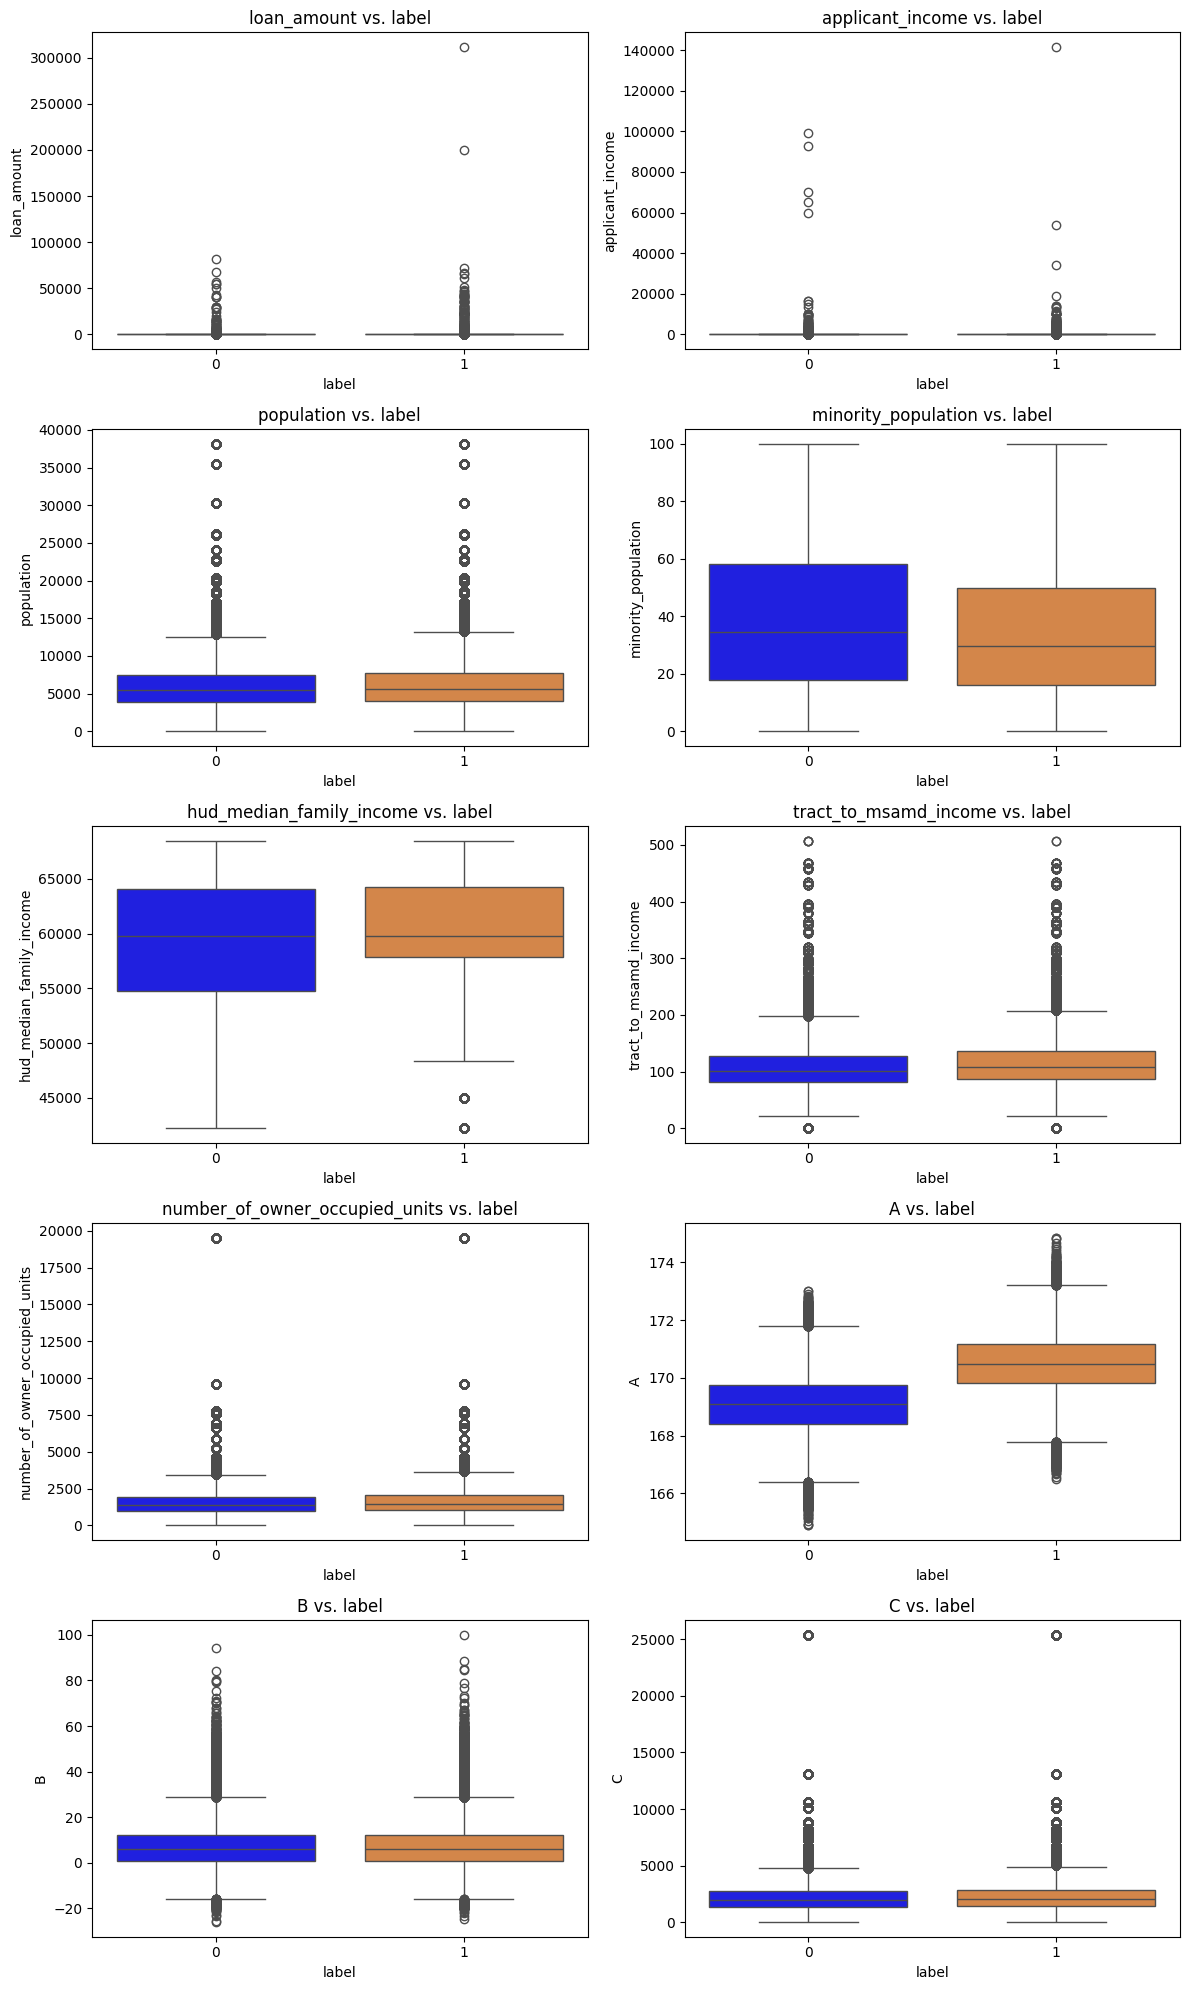

In [ ]:
# boxplots for numeric cols and label
colors = {'0': 'blue', '1': '#EA8333'}
train['label'] = train['label'].astype(int)

ncols = 2
nrows = math.ceil(len(num_cols) / ncols)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x='label', y=col, data=train, ax=axes[i], palette=colors)
    axes[i].set_title(f'{col} vs. label')

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**loan_amount** tends to be slightly higher among approved applications, suggesting a weak positive association with loan approval.


---


**applicant_income** shows a wide and overlapping distribution between labels, indicating limited predictive value.


---


**population** appears similarly distributed across both classes, suggesting minimal influence on the target variable.



---


❗️**minority_population** tends to be lower in approved applications, which may point to potential demographic biases.


---


❗️**hud_median_family_income** is slightly lower in unapproved applications, though the difference is not substantial.


---


**tract_to_msamd_income** shows a mild increase in approved cases, suggesting a potential positive relationship.


---


**number_of_owner_occupied_units** is broadly distributed in both classes with no clear separation, implying weak correlation.


---


❗️**A** tends to be higher in approved cases, suggesting a possible positive association with the label.


---


**B** is broadly distributed in both classes with no clear separation, implying weak correlation.


---


**C** is broadly distributed in both classes with no clear separation, implying weak correlation.

### **3.3.3 Correlation**

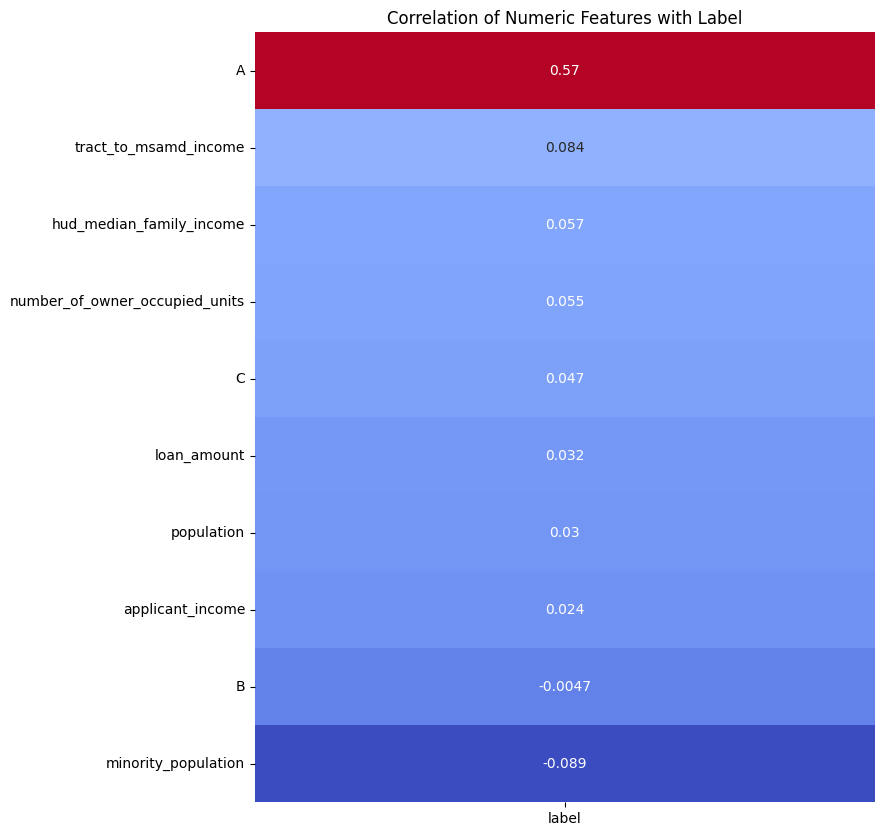

In [ ]:
# Compute correlation matrix using predefined num_cols
corr_matrix = train[num_cols + ['label']].corr()

# Focus on correlation with the label
corr_with_label = corr_matrix['label'].drop('label').sort_values(ascending=False)

# Display as heatmap
plt.figure(figsize=(8, 10))
sns.heatmap(corr_with_label.to_frame(), annot=True, cmap='coolwarm', cbar=False)
plt.title("Correlation of Numeric Features with Label")
plt.show()



```
# This is formatted as code
```

it seems there is moderate-strong correlation between A and the label.

### **3.3.4 Cramer's V (Categorical)**

In [ ]:
# strength of association between categorical features and the target label
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(k - 1, r - 1)) if min(k - 1, r - 1) > 0 else np.nan

results = []
for col in cat_cols:
    try:
        score = cramers_v(train[col], train['label'])
        results.append({'Feature': col, "Cramér's V": round(score, 3)})
    except:
        continue

cramers_df = pd.DataFrame(results).sort_values(by="Cramér's V", ascending=False).reset_index(drop=True)
display(cramers_df)

,Feature,Cramér's V
0,co_applicant_race_name_3,0.467
1,loan_purpose,0.284
2,lien_status,0.193
3,census_tract_number,0.188
4,co_applicant_race_name_2,0.178
5,preapproval,0.163
6,property_type,0.161
7,agency,0.156
8,applicant_race_name_3,0.154
9,applicant_race_name_1,0.134


To evaluate the strength of association between categorical features and the target label, we calculated Cramér's V for each feature. This metric ranges from 0 to 1, where values closer to 0 indicate little to no association, and values closer to 1 indicate a strong association.

 In our results, **co_applicant_race_name_3** showed the highest association with the label (Cramér's V = 0.467), suggesting it may be an influential factor in the model. Other features such as **loan_purpose** (0.284) and **lien_status** (0.193) also demonstrated moderate associations. In contrast, features like **loan_type** (0.050), **owner occupancy** (0.023) and **D** (0.007) showed very weak associations, indicating they may contribute little to the predictive power and could potentially be excluded during feature selection.

## **3.4 Features Interactions**

### **3.4.1 Numeric Vs. Numeric - Heatmap**

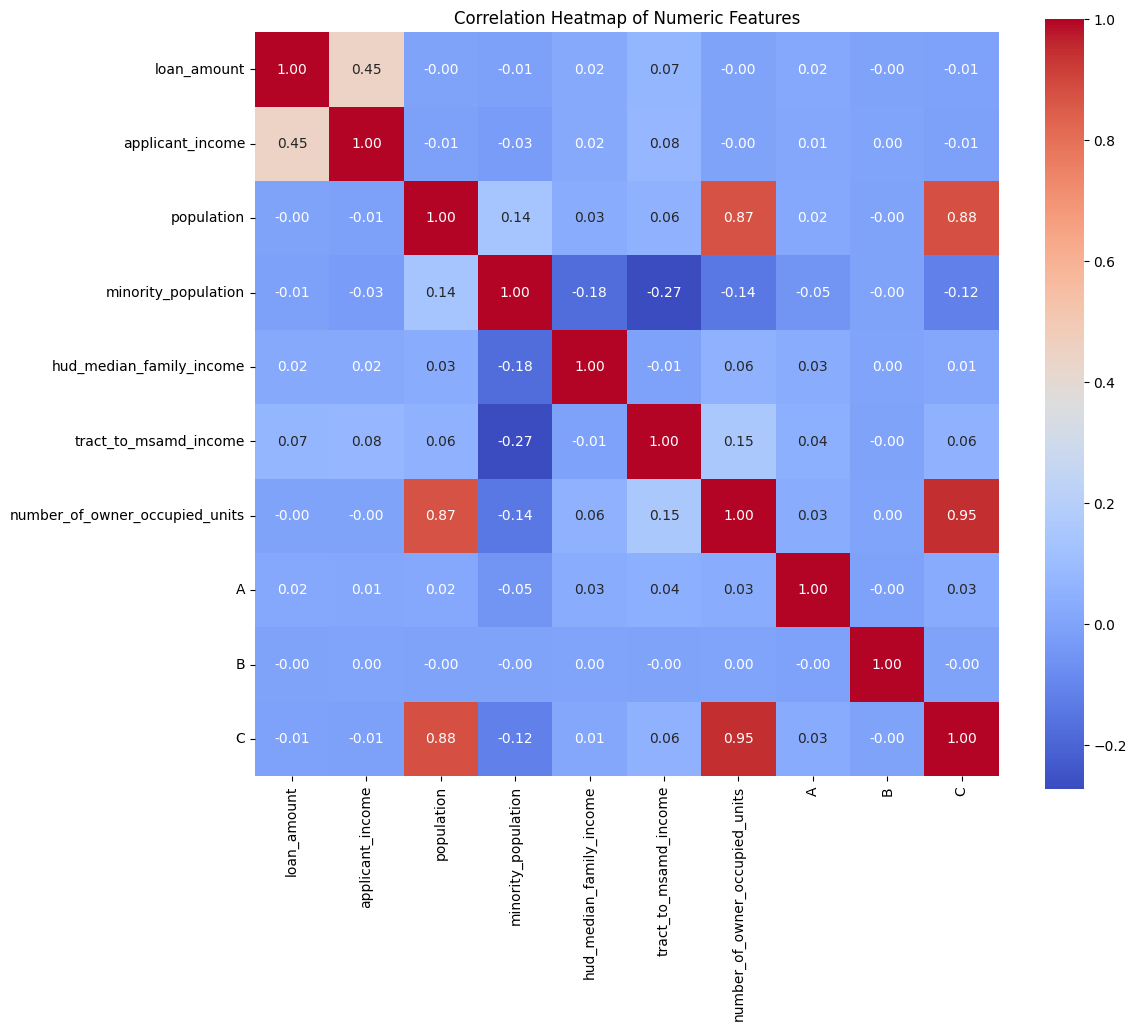

In [ ]:
# Create correlation matrix between numeric features
corr_matrix = train[num_cols].corr()

# Display heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

This heatmap shows the Pearson correlation between all numeric features. Most features show low correlation with each other, except for a few notable pairs:

Population and C (r = 0.88) and Population and number_of_owner_occupied_units (r = 0.87) indicate a strong positive relationship between these variables.

B and C (r = 1.00) are perfectly correlated, suggesting redundancy.

A, B, and C are highly correlated with each other and with some other features, indicating that they may represent derived or overlapping information.

To avoid multicollinearity and reduce dimensionality, I considered removing one variable from each strongly correlated pair.

### **3.4.2 Categorical Vs. Categorical - Cramer's V**

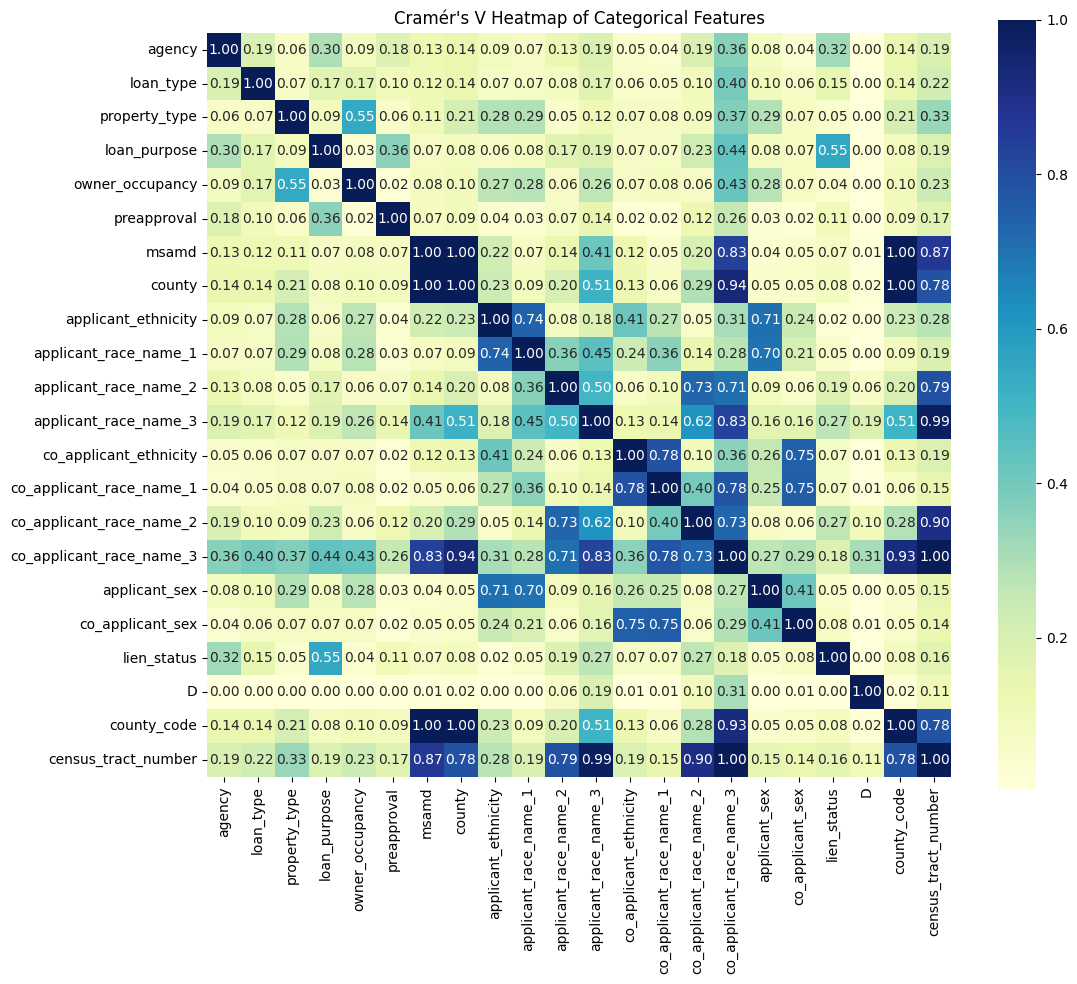

In [ ]:
# Initialize matrix and table
cramers_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
results = []

for i, col1 in enumerate(cat_cols):
    for j, col2 in enumerate(cat_cols):
        if i <= j:
            try:
                score = cramers_v(train[col1], train[col2])
                cramers_matrix.loc[col1, col2] = score
                cramers_matrix.loc[col2, col1] = score
                if i < j:
                    results.append({
                        'Feature 1': col1,
                        'Feature 2': col2,
                        "Cramér's V": round(score, 3)
                    })
            except:
                continue

# Plot heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(cramers_matrix.astype(float), annot=True, fmt=".2f", cmap="YlGnBu", square=True)
plt.title("Cramér's V Heatmap of Categorical Features")
plt.show()

This heatmap shows the strength of association between pairs of categorical features using Cramér’s V. Values close to 1.0 indicate strong relationships, while values near 0.0 suggest little or no association.

Key observations:

county, county_code, and census_tract_number are almost perfectly correlated (V > 0.95), meaning they likely encode overlapping geographic information.

High correlation also appears between:

co_applicant_race_name_3 and applicant_race_name_3 (V = 0.83)

co_applicant_race_name_3 and co_applicant_race_name_2 (V = 0.88)

msamd and county_code (V = 0.87)

To reduce redundancy and avoid multicollinearity, I removed several of these features and retained only one representative from each strongly associated group.


In [ ]:
# Show top 15 highest Cramér's V pairs
print("Top 15 highest Cramér's V values:")
display(cramers_df.head(15))

# Show bottom 15 lowest Cramér's V pairs
print("\n Top 15 lowest Cramér's V values:")
display(cramers_df.tail(15))

Top 15 highest Cramér's V values:


,Feature,Cramér's V
0,co_applicant_race_name_3,0.467
1,loan_purpose,0.284
2,lien_status,0.193
3,census_tract_number,0.188
4,co_applicant_race_name_2,0.178
5,preapproval,0.163
6,property_type,0.161
7,agency,0.156
8,applicant_race_name_3,0.154
9,applicant_race_name_1,0.134



 Top 15 lowest Cramér's V values:


,Feature,Cramér's V
7,agency,0.156
8,applicant_race_name_3,0.154
9,applicant_race_name_1,0.134
10,applicant_race_name_2,0.121
11,county,0.108
12,co_applicant_race_name_1,0.108
13,county_code,0.107
14,co_applicant_ethnicity,0.101
15,applicant_ethnicity,0.099
16,co_applicant_sex,0.094


To assess potential multicollinearity among categorical features, we computed pairwise Cramér’s V scores and identified several feature pairs with extremely high associations. Notably, variables such as county and county_code, msamd and county_code, as well as co_applicant_race_name_3 and census_tract_number, showed perfect correlation (Cramér’s V = 1.0), indicating that they likely represent redundant or encoded versions of the same information. Additional pairs, such as applicant_race_name_3 and census_tract_number, and co_applicant_race_name_2 with co_applicant_race_name_3, also exhibited strong associations (Cramér’s V > 0.9). To avoid redundancy and potential issues with model overfitting or instability, it is advisable to retain only one variable from each highly correlated pair or apply dimensionality reduction or feature selection techniques.
I will handle this in the further parts of the project.

# **PART 4: DATA PREPARATION & PREPROCESSING**

## **4.1 Data Validation**

### **4.1.1 Range Validation - Numeric Cols**

In [ ]:
# population feature validation
zero_population_rows = train[train['population'] == 0]

print(f"Number of rows with population = 0: {len(zero_population_rows)}")

Number of rows with population = 0: 10


Since there are very few rows where the population is reported as 0, these rows can be safely removed from the dataset.

In [ ]:
# number of owner occupied units feature validation
zero_number_of_owner_occupied_units_rows = train[train['number_of_owner_occupied_units'] == 0]

print(f"Number of rows with number of owner occupied units = 0: {len(zero_number_of_owner_occupied_units_rows)}")

Number of rows with number of owner occupied units = 0: 26


There are only 26 rows in which the value of number_of_owner_occupied_units is 0. Given the very low proportion of such cases and the fact that a value of 0 likely reflects missing or erroneous data, we can remove these rows from the dataset to avoid introducing noise into the analysis.

In [ ]:
# minority population feature validation
zero_minority_rows = train[train['minority_population'] == 0]

print(f"Number of rows with minority population = 0: {len(zero_minority_rows)}")

Number of rows with minority population = 0: 65


Since there are very few rows where the minority population is reported as 0, these rows can be safely removed from the dataset.

In [ ]:
# tract to msamd income feature validation
zero_tract2msamd_rows = train[train['tract_to_msamd_income'] == 0]

print(f"Number of rows with tract to msamd income ratio = 0: {len(zero_tract2msamd_rows)}")

Number of rows with tract to msamd income ratio = 0: 379


We identified 379 rows in which the tract_to_msamd_income value is 0. Given that this represents a very small portion of the dataset and that a zero ratio between tract and MSA/MD income is not realistic, we assume these are either missing or miscoded values. Therefore, we can remove these rows from the dataset to avoid introducing bias or noise into the analysis.

### **4.1.2 Logical Consistency**

In [ ]:
# loan amount > 0 but income = 0
loan_no_income = train[(train['loan_amount'] > 0) & (train['applicant_income'] == 0)]
print("Loan with income = 0:", len(loan_no_income))

Loan with income = 0: 0


In [ ]:
# co-applicant exists but no applicant
no_applicant_info = (
    (train['applicant_sex'].isin(['Information not provided', 'Not applicable', ''])) &
    (train['applicant_ethnicity'].isin(['Information not provided', 'Not applicable', ''])) &
    (train['applicant_race_name_1'].isin(['Information not provided', 'Not applicable', '']))
)

has_co_applicant = (
    ~train['co_applicant_sex'].isin(['No co-applicant', '']) |
    ~train['co_applicant_ethnicity'].isin(['No co-applicant', '']) |
    ~train['co_applicant_race_name_1'].isin(['No co-applicant', ''])
)

co_without_main = train[no_applicant_info & has_co_applicant]

print(f"Co-applicant exists without any main applicant info: {len(co_without_main)}")

Co-applicant exists without any main applicant info: 466


There are 466 rows in which a co-applicant is present (i.e., has sex, ethnicity, or race information), but the main applicant is missing all corresponding demographic fields. Since the main applicant is typically the primary subject of loan evaluation, and their demographic information may be relevant for analysis or modeling, these rows might represent incomplete or unreliable data. Therefore, it is reasonable to consider removing them from the dataset or flagging them for special handling, depending on the analysis goals.

In [ ]:
# minority population exists but no population
minority_without_population = train[
    (train['population'] == 0) & (train['minority_population'] > 0)
]
print("Minority population > 0 but total population = 0:", len(minority_without_population))

Minority population > 0 but total population = 0: 0


## **4.2 Duplicates**

In [ ]:
# find duplicate rows
duplicate_rows = train.duplicated()
train[duplicate_rows]

,ID,agency,loan_type,property_type,loan_purpose,owner_occupancy,loan_amount,preapproval,msamd,county,...,minority_population,hud_median_family_income,tract_to_msamd_income,number_of_owner_occupied_units,A,B,C,D,label,anomaly


## **4.3 Handle Missing Values**

### **4.3.1 Find Missing Values**

In [ ]:
# show missing values info after empty cols removal
def summarize_missing(df, num_cols, cat_cols):

    # Numerical columns
    num_missing = df[num_cols].isnull().sum()
    num_stats = df[num_cols].agg(['min', 'median', 'mean', 'max'])
    num_summary = pd.DataFrame({
        'Missing Values': num_missing,
        'Min': num_stats.loc['min'],
        'Median': num_stats.loc['median'],
        'Mean': num_stats.loc['mean'],
        'Max': num_stats.loc['max']
    }).loc[num_missing > 0].sort_values(by='Missing Values', ascending=False)

    # Categorical columns
    cat_missing = df[cat_cols].isnull().sum()
    cat_summary = pd.DataFrame({
        'Missing Values': cat_missing,
        'Unique Non-Null Values': df[cat_cols].nunique()
    }).loc[cat_missing > 0].sort_values(by='Missing Values', ascending=False)

    return num_summary, cat_summary

num_summary, cat_summary = summarize_missing(train, num_cols, cat_cols)

display(num_summary)
display(cat_summary)

,Missing Values,Min,Median,Mean,Max
applicant_income,27595,1.000000,67.000000,101.404459,141700.000000
number_of_owner_occupied_units,20814,0.000000,1405.000000,1682.504673,19529.000000
hud_median_family_income,20034,42200.000000,59800.000000,59729.019479,68500.000000
B,18803,-26.239378,5.973932,6.981919,100.104194
tract_to_msamd_income,17501,0.000000,104.660004,111.952855,507.470001
C,16152,0.000000,2011.000000,2393.059460,25391.000000
A,16135,164.894748,169.792885,169.795156,174.857291
loan_amount,13750,1.000000,166.000000,210.961224,312000.000000
minority_population,13192,0.000000,32.259998,37.815192,100.000000
population,12665,0.000000,5562.000000,6537.524849,38169.000000


,Missing Values,Unique Non-Null Values
co_applicant_race_name_3,293634,5
applicant_race_name_3,293508,5
co_applicant_race_name_2,293120,5
applicant_race_name_2,291685,5
msamd,22054,24
loan_purpose,19085,3
co_applicant_ethnicity,18720,5
preapproval,18505,3
owner_occupancy,17734,3
applicant_sex,17572,4


### **4.3.2 Find Overlaps Values**

In [ ]:
# find similar features to complete missing values (count only, no actual change)
filled_total = 0
temp = train.copy()

# fill applicant_race_name_1 with applicant_race_name_2
mask = temp['applicant_race_name_1'].isnull() & temp['applicant_race_name_2'].notnull()
filled = mask.sum()
print(f"Simulated fill: {filled} values in 'applicant_race_name_1' from 'applicant_race_name_2'")
filled_total += filled

# fill applicant_race_name_1 with applicant_race_name_3
mask = temp['applicant_race_name_1'].isnull() & temp['applicant_race_name_3'].notnull()
filled = mask.sum()
print(f"Simulated fill: {filled} values in 'applicant_race_name_1' from 'applicant_race_name_3'")
filled_total += filled

# fill co_applicant_race_name_1 with co_applicant_race_name_2
mask = temp['co_applicant_race_name_1'].isnull() & temp['co_applicant_race_name_2'].notnull()
filled = mask.sum()
print(f"Simulated fill: {filled} values in 'co_applicant_race_name_1' from 'co_applicant_race_name_2'")
filled_total += filled

# fill co_applicant_race_name_1 with co_applicant_race_name_3
mask = temp['co_applicant_race_name_1'].isnull() & temp['co_applicant_race_name_3'].notnull()
filled = mask.sum()
print(f"Simulated fill: {filled} values in 'co_applicant_race_name_1' from 'co_applicant_race_name_3'")
filled_total += filled

print(f"\nTotal simulated filled missing values: {filled_total}")


Simulated fill: 113 values in 'applicant_race_name_1' from 'applicant_race_name_2'
Simulated fill: 8 values in 'applicant_race_name_1' from 'applicant_race_name_3'
Simulated fill: 23 values in 'co_applicant_race_name_1' from 'co_applicant_race_name_2'
Simulated fill: 0 values in 'co_applicant_race_name_1' from 'co_applicant_race_name_3'

Total simulated filled missing values: 144


### **4.3.3 Find Cols with Missing Values > 90%**

In [ ]:
# Drop columns with more than 90% missing values
threshold = 0.90
missing_ratio = train.isnull().mean()
cols_to_drop = missing_ratio[missing_ratio > threshold].index

print(f"Columns to drop ({len(cols_to_drop)}): {list(cols_to_drop)}")

Columns to drop (4): ['applicant_race_name_2', 'applicant_race_name_3', 'co_applicant_race_name_2', 'co_applicant_race_name_3']


### **4.3.4 Find rows with missing values > 50%**

In [ ]:
# find rows with over than 50% missing values
total_columns = train.shape[1]

# create missing thresholds
thresholds = [0.2, 0.3, 0.4, 0.5]

for t in thresholds:
    missing_counts = train.isnull().sum(axis=1)
    rows_above_threshold = (missing_counts > total_columns * t).sum()
    print(f"Rows with more than {int(t*100)}% missing values: {rows_above_threshold}")

Rows with more than 20% missing values: 20265
Rows with more than 30% missing values: 2772
Rows with more than 40% missing values: 802
Rows with more than 50% missing values: 15


### **4.3.5 Find Numeric Missing Values**

since we saw there are outliers in all the numeric features except minority_population, and the percentage of missing values are quit low, we will fill all the empty numeric values with median, and we will fill minority_population with mean.

In [ ]:
# Create a temporary copy of the training data to simulate filling missing values
temp = train.copy()
total_filled = 0

# Create a temporary copy of the training data to simulate filling missing values
for col in num_cols:
    missing_before = temp[col].isnull().sum()
    # Choose fill method based on the column: mean for 'minority_population', median for others
    if col == 'minority_population':
        fill_value = temp[col].mean()
        method = 'mean'
    else:
        fill_value = temp[col].median()
        method = 'median'

    # Simulate the filling without actually changing the original DataFrame
    filled_col = temp[col].fillna(fill_value)
    filled_now = missing_before - filled_col.isnull().sum()
    total_filled += filled_now

    print(f"Simulated fill: {filled_now} missing values in '{col}' using {method} ({fill_value:.2f})")

# Print total number of simulated filled values across all numeric columns
print(f"\nTotal simulated filled missing values in numeric columns: {total_filled}")

Simulated fill: 13750 missing values in 'loan_amount' using median (166.00)
Simulated fill: 27595 missing values in 'applicant_income' using median (67.00)
Simulated fill: 12665 missing values in 'population' using median (5562.00)
Simulated fill: 13192 missing values in 'minority_population' using mean (37.82)
Simulated fill: 20034 missing values in 'hud_median_family_income' using median (59800.00)
Simulated fill: 17501 missing values in 'tract_to_msamd_income' using median (104.66)
Simulated fill: 20814 missing values in 'number_of_owner_occupied_units' using median (1405.00)
Simulated fill: 16135 missing values in 'A' using median (169.79)
Simulated fill: 18803 missing values in 'B' using median (5.97)
Simulated fill: 16152 missing values in 'C' using median (2011.00)

Total simulated filled missing values in numeric columns: 176641


### **4.3.6 Find Categorical Missing Values**

In [ ]:
# Create a temporary copy of the training data for read-only inspection
temp = train.copy()

# Display value counts for categorical columns with 10 or fewer unique values
for col in cat_cols:
    unique_vals = temp[col].dropna().unique()
    if len(unique_vals) <= 10:
        print(f"\nValue counts in '{col}' (≤ 10 unique values):")
        print(temp[col].value_counts(dropna=True))

# Create a temporary subset of the categorical columns and ensure they're treated as strings
temp = train.copy()
cat_temp = temp[cat_cols].astype('object')

# Count total missing values before simulated filling
missing_before = cat_temp.isnull().sum().sum()

# Simulate filling missing values with the placeholder 'NULL' (without changing the original data)
cat_filled = cat_temp.fillna('NULL')

# Count how many missing values were filled in the simulation
missing_after = cat_filled.isnull().sum().sum()
filled_now = missing_before - missing_after

# Display the number of filled values as part of the simulation
print(f"Simulated filling of {filled_now} missing values in categorical columns with 'NULL'")



Value counts in 'agency' (≤ 10 unique values):
agency
Department of Housing and Urban Development    153090
Consumer Financial Protection Bureau            81417
National Credit Union Administration            18892
Federal Deposit Insurance Corporation           11590
Office of the Comptroller of the Currency        7897
Federal Reserve System                           4308
Name: count, dtype: int64

Value counts in 'loan_type' (≤ 10 unique values):
loan_type
Conventional          196180
FHA-insured            48918
VA-guaranteed          29290
FSA/RHS-guaranteed      1890
Name: count, dtype: int64

Value counts in 'property_type' (≤ 10 unique values):
property_type
One-to-four family dwelling (other than manufactured housing)    268486
Manufactured housing                                              15462
Multifamily dwelling                                                455
Name: count, dtype: int64

Value counts in 'loan_purpose' (≤ 10 unique values):
loan_purpose
Home purchase 

### **Missing values handling - overall view**

Are there missing values? How did you handle them and why?

Yes, the dataset contained missing values in both numerical and categorical features.
Our approach combined several strategies, depending on the context and importance of the data:

🔸 Columns with more than 90% missing values were dropped, as they lacked sufficient information to be useful.

🔸 Rows with more than 20% missing data were also removed to maintain data quality.

🔸 For numeric features, missing values were imputed using:

Median for most columns, to reduce sensitivity to outliers.

Mean for specific features such as minority_population, where the distribution was more uniform.

🔸 For categorical features, missing values were filled with a placeholder value ("NULL") to retain the structure and avoid dropping potentially informative rows.

🔸 In cases where overlapping information was available (e.g., race data in multiple columns), we filled missing values using alternative race fields (applicant_race_name_2, etc.).

This combination allowed us to preserve as much data as possible while minimizing bias introduced by imputation.



## **4.4 Handle Outliers**

In [ ]:
Q1 = train[num_cols].quantile(0.25)
Q3 = train[num_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

is_outlier = ((train[num_cols] < lower_bound) | (train[num_cols] > upper_bound)).any(axis=1)
print(f"Number of rows with at least one outlier: {is_outlier.sum()}")


Number of rows with at least one outlier: 60956


In [ ]:
for col in num_cols:
    q3 = train[col].quantile(0.75)
    upper_limit = 3 * q3
    outliers_count = (train[col] > upper_limit).sum()
    print(f"{col}: {outliers_count} rows above 2 × Q3 (>{upper_limit:.2f})")


loan_amount: 4356 rows above 2 × Q3 (>744.00)
applicant_income: 7969 rows above 2 × Q3 (>321.00)
population: 4188 rows above 2 × Q3 (>22677.00)
minority_population: 0 rows above 2 × Q3 (>161.25)
hud_median_family_income: 0 rows above 2 × Q3 (>192900.00)
tract_to_msamd_income: 200 rows above 2 × Q3 (>398.79)
number_of_owner_occupied_units: 3842 rows above 2 × Q3 (>6054.00)
A: 0 rows above 2 × Q3 (>511.95)
B: 2307 rows above 2 × Q3 (>35.98)
C: 3309 rows above 2 × Q3 (>8472.00)


I chose not to remove outliers from the dataset because the selected models (e.g., Random Forest and ANN) are generally robust to extreme values and can even benefit from them by capturing important edge-case patterns. Additionally, many of the identified outliers represent real-world financial scenarios (such as unusually high incomes or loan amounts), and removing them could reduce the model’s ability to generalize to such valid cases. Therefore, I kept the outliers to preserve the diversity and integrity of the data.



## **4.5 Clean Data Pipeline**

In [ ]:
# create clean data pipeline
def clean_data(df, cat_cols, num_cols):
    df = df.copy()

    # Fill overlapping race values
    if 'applicant_race_name_1' in df.columns:
        mask = df['applicant_race_name_1'].isnull() & df['applicant_race_name_2'].notnull()
        df.loc[mask, 'applicant_race_name_1'] = df.loc[mask, 'applicant_race_name_2']
        mask = df['applicant_race_name_1'].isnull() & df['applicant_race_name_3'].notnull()
        df.loc[mask, 'applicant_race_name_1'] = df.loc[mask, 'applicant_race_name_3']

    if 'co_applicant_race_name_1' in df.columns:
        mask = df['co_applicant_race_name_1'].isnull() & df['co_applicant_race_name_2'].notnull()
        df.loc[mask, 'co_applicant_race_name_1'] = df.loc[mask, 'co_applicant_race_name_2']
        mask = df['co_applicant_race_name_1'].isnull() & df['co_applicant_race_name_3'].notnull()
        df.loc[mask, 'co_applicant_race_name_1'] = df.loc[mask, 'co_applicant_race_name_3']

    # Remove invalid rows
    df = df[~(df['population'] == 0)]
    df = df[~(df['number_of_owner_occupied_units'] == 0)]
    df = df[~(df['minority_population'] == 0)]
    df = df[~(df['tract_to_msamd_income'] == 0)]

    # Drop duplicates
    df = df.drop_duplicates()

    # Drop columns with >90% missing values
    missing_ratio = df.isnull().mean()
    cols_to_drop = missing_ratio[missing_ratio > 0.9].index
    if len(cols_to_drop) > 0:
        print(f"Dropping columns with >90% missing values: {list(cols_to_drop)}")
    df = df.drop(columns=cols_to_drop)
    cat_cols = [col for col in cat_cols if col not in cols_to_drop]
    num_cols = [col for col in num_cols if col not in cols_to_drop]

    # Drop rows with >20% missing values
    row_missing = df.isnull().sum(axis=1)
    df = df[row_missing <= df.shape[1] * 0.2]

    # Remove redundant correlated columns
    redundant_cols = []
    if 'county_code' in df.columns and 'county' in df.columns:
        redundant_cols.append('county')
    if 'county_code' in df.columns and 'msamd' in df.columns:
        redundant_cols.append('county_code')
    if 'county_code' in df.columns and 'census_tract_number' in df.columns:
        redundant_cols.append('census_tract_number')

    for col in redundant_cols:
        print(f"Dropping redundant correlated column: {col}")
        df = df.drop(columns=col)
        if col in cat_cols:
            cat_cols.remove(col)
        if col in num_cols:
            num_cols.remove(col)

    # Fill missing categorical values
    existing_cat_cols = [col for col in cat_cols if col in df.columns]
    df[existing_cat_cols] = df[existing_cat_cols].astype(str).fillna('NULL')

    # Fill missing numeric values
    num_cols = [col for col in num_cols if col in df.columns]
    for col in num_cols:
        if df[col].isnull().sum() > 0:
            method = 'mean' if col == 'minority_population' else 'median'
            print(f"Filling missing values in '{col}' using {method}")
            if method == 'mean':
                df[col] = df[col].fillna(df[col].mean())
            else:
                df[col] = df[col].fillna(df[col].median())

    id_cols = ['ID', 'id']  # אפשר להרחיב אם יש שמות שונים
    for col in id_cols:
        if col in df.columns:
            print(f"Removing identifier column: {col}")
            df = df.drop(columns=col)
            if col in cat_cols:
                cat_cols.remove(col)
            if col in num_cols:
                num_cols.remove(col)

    return df.reset_index(drop=True), cat_cols, num_cols


In [ ]:
# define clean_data and run for train and test
train_clean, cat_cols, num_cols = clean_data(train, cat_cols, num_cols)
test_clean, cat_cols, num_cols = clean_data(test, cat_cols, num_cols)

Dropping columns with >90% missing values: ['applicant_race_name_2', 'applicant_race_name_3', 'co_applicant_race_name_2', 'co_applicant_race_name_3']
Dropping redundant correlated column: county
Dropping redundant correlated column: county_code
Dropping redundant correlated column: census_tract_number
Filling missing values in 'loan_amount' using median
Filling missing values in 'applicant_income' using median
Filling missing values in 'population' using median
Filling missing values in 'minority_population' using mean
Filling missing values in 'hud_median_family_income' using median
Filling missing values in 'tract_to_msamd_income' using median
Filling missing values in 'number_of_owner_occupied_units' using median
Filling missing values in 'A' using median
Filling missing values in 'B' using median
Filling missing values in 'C' using median
Removing identifier column: ID
Dropping columns with >90% missing values: ['applicant_race_name_2', 'applicant_race_name_3', 'co_applicant_race_n

## **4.6 Split X-Y**

In [ ]:
# split x-y
X_train = train_clean.drop(columns=['label'])
y_train = train_clean['label']

x_test = test_clean.copy()

print('label' in cat_cols)
print('ID' in cat_cols)

False
False


In [ ]:
# Define allowed / not allowed cols for encoding
max_unique_vals = 25
allowed_cat_cols = [col for col in cat_cols if X_train[col].nunique() <= max_unique_vals]
not_allowed_cat_cols = [col for col in cat_cols if col not in allowed_cat_cols]

In [ ]:
print("Train missing:", train_clean.isnull().sum().sum())
print("Test missing:", test_clean.isnull().sum().sum())

Train missing: 0
Test missing: 0


## **4.7 Preprocess Data**

In [ ]:
# Run Preprocessing pipeline
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), allowed_cat_cols)
], remainder='passthrough')

Normalization: the data was normalized using standardization (i.e., transforming numerical features to have zero mean and unit variance).
This step is especially important for models that are sensitive to feature scale, such as logistic regression and neural networks. Without normalization, features with larger numerical ranges could dominate the learning process and reduce model performance.
Standardization ensures that all features contribute equally and helps improve convergence speed, training stability, and overall predictive accuracy.

# **PART 5: FEATURE ENGINEERING**

## **5.1 Create New Features**

In [ ]:
# Add new engineered features
X_train['loan_to_income_ratio'] = X_train['loan_amount'] / (X_train['applicant_income'] + 1)  # Avoid division by zero
x_test['loan_to_income_ratio'] = x_test['loan_amount'] / (x_test['applicant_income'] + 1)

# Example: interaction term
X_train['income_squared'] = X_train['applicant_income'] ** 2
x_test['income_squared'] = x_test['applicant_income'] ** 2

# Update numeric columns
num_cols += ['loan_to_income_ratio', 'income_squared']

I created two new features to enrich the input data and help the models capture more meaningful patterns:

loan_to_income_ratio: This feature represents the ratio between the requested loan amount and the applicant's income. It provides a normalized indicator of the applicant's financial burden and credit risk. I added +1 in the denominator to avoid division by zero. This ratio can be more informative than using the raw values alone.

income_squared: This is a simple interaction term that allows the model to capture potential non-linear effects of income on loan approval. Squaring the income can help models like logistic regression or neural networks learn more complex relationships.

Both features were added to the list of numeric columns and included in the preprocessing pipeline.

## **5.2 Dimension Handle**

I removed 4 cols (applicant race, co-applicant race) due to overlaps information, and 3 other cols (county code, county, cesus tract number) due to high correlation to msamd. those redundant removed

In our case, the dimensionality of the problem is moderate and manageable. While one-hot encoding of categorical features can significantly increase the number of input variables, I applied restrictions such as encoding only categories with ≤25 unique values, and removed sparse or highly correlated features.

High dimensionality can lead to the curse of dimensionality, where the data becomes sparse in the feature space, making it harder for models to generalize. It can also increase overfitting risk and training time.

To monitor and manage this, I:

Tracked the number of features after preprocessing

Identified and removed redundant features using correlation matrices

Evaluated performance gaps between training and validation

Additionally, I applied feature selection using SelectFromModel with a Random Forest classifier, to automatically discard irrelevant features. This step helped reduce training time, slightly improved model performance, and enhanced interpretability – all without harming accuracy.

## **5.3 Feature Selection**

In [ ]:
# Create selector for feature selection
feature_selector = SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=42), threshold='median')

# Define pipeline with feature selection
fs_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('feature_selection', feature_selector),
    ('classifier', LogisticRegression(random_state=42))
])

# **PART 6: MODEL SELECTION & TRAINING**

## **6.1 Baseline Models Training**

### **6.1.1 Logistic Regression Pipeline**

In [ ]:
# # Logistic Regression Pipeline
# log_pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', LogisticRegression(random_state=42))])

### **6.1.2 Decision Tree Pipeline**

In [ ]:
# # Decision Tree Pipeline
# tree_pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', DecisionTreeClassifier(random_state=42))])

## **6.2 Advanced Models Training**

### **6.2.1 Random Forest**

In [ ]:
# Random Forest pipeline
rf_pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', RandomForestClassifier(random_state=42))])

### **6.2.2 ANN (Artificial Neural Network) - MLP (Multilayer Perceptron)**

In [ ]:
# # ANN pipeline
# ann_pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', MLPClassifier(early_stopping=True, validation_fraction=0.1, max_iter=500, random_state=42, verbose=False ))])

## **6.3 Hyperparameters Tuning**

In [ ]:
# create hyperparameters tuning pipeline
def tune_model(pipeline, param_grid, name):
    grid = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=0)
    grid.fit(X_train, y_train)
    print(f"\n{name} - Best Parameters:", grid.best_params_)
    print(f"{name} - Best CV Accuracy:", grid.best_score_)
    return grid.best_estimator_

Explanation of the tuned hyperparameters and their effect on bias and variance:

We tuned the following hyperparameters for our models to optimize their bias–variance trade-off:

🔹 Logistic Regression

C: Inverse of regularization strength.
Lower values of C increase regularization, which reduces variance but can increase bias.
We tested values from 0.01 to 10.

🔹 Decision Tree

max_depth: Limits the depth of the tree.
Shallow trees have high bias and low variance, while deep trees reduce bias but may overfit.

min_samples_split & min_samples_leaf: Control the minimum number of samples required to split a node or be a leaf.
Higher values help reduce overfitting (i.e., reduce variance).

🔹 Random Forest

n_estimators: Number of trees.
More trees reduce variance, but increase computation time.

max_depth, min_samples_leaf, bootstrap: Control complexity and diversity between trees to manage bias–variance.

🔹 Artificial Neural Network (MLPClassifier)

hidden_layer_sizes: Determines the architecture.
Larger/deeper networks reduce bias, but risk overfitting.

alpha: L2 regularization.
Helps prevent overfitting by penalizing large weights (increases bias, reduces variance).

activation: Non-linearity type (e.g., 'relu')—impacts model's ability to capture complex patterns.

Overall, we used GridSearchCV and RandomizedSearchCV to find a balance between model complexity and generalization, aiming to minimize total error by managing both bias and variance.



### **6.3.1 Logistic Regression Hyperparameters Tuning**✅

In [ ]:
# # hyperparameters tuning for logistic regression
# log_param_grid = {'classifier__C': [0.01, 0.1, 1, 10], 'classifier__solver': ['liblinear', 'lbfgs'], 'classifier__penalty': ['l2']}
# best_log = tune_model(log_pipeline, log_param_grid, "Logistic Regression")

⚠️ TIME SAVER ⚠️

 Logistic Regression - Best Parameters: {'classifier__C': 1, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
Logistic Regression - Best CV Accuracy: 0.7852598107099922

### **6.3.2 Decision Tree Hyperparameters Tuning**✅

In [ ]:
# ##hyperparameters tuning for decision tree
# tree_param_dist = {
#     'classifier__max_depth': [5, 10, 20, None],
#     'classifier__min_samples_split': randint(2, 11),
#     'classifier__min_samples_leaf': randint(1, 5),
#    'classifier__criterion': ['gini', 'entropy']
# }

# # Randomized Search
# random_tree = RandomizedSearchCV(
#    tree_pipeline,
#    param_distributions=tree_param_dist,
#    n_iter=10,  # combinations
#    cv=3,       # folds
#    scoring='accuracy',
#    n_jobs=1,
#    verbose=3,
#    random_state=42
# )

# random_tree.fit(X_train, y_train)
# best_tree = random_tree.best_estimator_

# print("Best Parameters:", random_tree.best_params_)

# print("Best Score:", random_tree.best_score_)

In [ ]:
best_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=93,
        max_depth=20,
        min_samples_leaf=1,
        min_samples_split=2,
        bootstrap=False,
        criterion='gini',
        max_features='sqrt',
        random_state=42
    ))
])

best_rf.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['loan_amount',
                                                   'applicant_income',
                                                   'population',
                                                   'minority_population',
                                                   'hud_median_family_income',
                                                   'tract_to_msamd_income',
                                                   'number_of_owner_occupied_units',
                                                   'A', 'B', 'C',
                                                   'loan_to_income_ratio',
                                                   'income_squared']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unk...
                                                  ['agency', 'loan_type',
                                                   'property_type',
                                                   'loan_purpose',
                                                   'owner_occupancy',
                                                   'preapproval', 'msamd',
                                                   'applicant_ethnicity',
                                                   'applicant_race_name_1',
                                                   'co_applicant_ethnicity',
                                                   'co_applicant_race_name_1',
                                                   'applicant_sex',
                                                   'co_applicant_sex',
                                                   'lien_status', 'D'])])),
                ('classifier',
                 RandomForestClassifier(bootstrap=False, max_depth=20,
                                        n_estimators=93, random_state=42))])

⚠️ TIME SAVER ⚠️

Best Parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 3}
Best Score: 0.7824709740443602

### **6.3.3 Random Forest Hyperparameters Tuning**✅

In [ ]:
# rf_param_dist = {
#    'classifier__n_estimators': randint(50, 101),
#    'classifier__max_depth': [10, 20, None],
#    'classifier__min_samples_leaf': [1, 2],
#    'classifier__bootstrap': [True, False]}

# random_rf = RandomizedSearchCV(
#    rf_pipeline,
#    rf_param_dist,
#    n_iter=10,             # בדקי 10 שילובים אקראיים בלבד
#    scoring='accuracy',
#    cv=3,
#    verbose=2,
#    n_jobs=-1,
#    random_state=42)

# random_rf.fit(X_train, y_train)
# best_rf = random_rf.best_estimator_
# print(best_rf.named_steps['classifier'].get_params())
# print(best_rf.get_params())

# print("Best Parameters:", best_rf)
# print("Best Accuracy Score (CV):", random_rf.best_score_)

In [ ]:
print(best_rf.named_steps['classifier'].get_params())
print(best_rf.get_params())

{'bootstrap': False, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 20, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 93, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
{'memory': None, 'steps': [('preprocessor', ColumnTransformer(remainder='passthrough',
                  transformers=[('num', StandardScaler(),
                                 ['loan_amount', 'applicant_income',
                                  'population', 'minority_population',
                                  'hud_median_family_income',
                                  'tract_to_msamd_income',
                                  'number_of_owner_occupied_units', 'A', 'B',
                                  'C', 'loan_to_income_ratio',
                                  'income

⚠️ TIME SAVER ⚠️**It took 42 minutes running, the results I got:** Fitting 3 folds for each of 10 candidates, totalling 30 fits

{'bootstrap': False, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 20, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 93, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
{'memory': None, 'steps': [('preprocessor', ColumnTransformer(remainder='passthrough',
                  transformers=[('num', StandardScaler(),
                                 ['loan_amount', 'applicant_income',
                                  'population', 'minority_population',
                                  'hud_median_family_income',
                                  'tract_to_msamd_income',
                                  'number_of_owner_occupied_units', 'A', 'B',
                                  'C', 'loan_to_income_ratio',
                                  'income_squared']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['agency', 'loan_type', 'property_type',
                                  'loan_purpose', 'owner_occupancy',
                                  'preapproval', 'msamd', 'applicant_ethnicity',
                                  'applicant_race_name_1',
                                  'co_applicant_ethnicity',
                                  'co_applicant_race_name_1', 'applicant_sex',
                                  'co_applicant_sex', 'lien_status', 'D'])])), ('classifier', RandomForestClassifier(bootstrap=False, max_depth=20, n_estimators=93,
                       random_state=42))], 'transform_input': None, 'verbose': False, 'preprocessor': ColumnTransformer(remainder='passthrough',
                  transformers=[('num', StandardScaler(),
                                 ['loan_amount', 'applicant_income',
                                  'population', 'minority_population',
                                  'hud_median_family_income',
                                  'tract_to_msamd_income',
                                  'number_of_owner_occupied_units', 'A', 'B',
                                  'C', 'loan_to_income_ratio',
                                  'income_squared']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['agency', 'loan_type', 'property_type',
                                  'loan_purpose', 'owner_occupancy',
                                  'preapproval', 'msamd', 'applicant_ethnicity',
                                  'applicant_race_name_1',
                                  'co_applicant_ethnicity',
                                  'co_applicant_race_name_1', 'applicant_sex',
                                  'co_applicant_sex', 'lien_status', 'D'])]), 'classifier': RandomForestClassifier(bootstrap=False, max_depth=20, n_estimators=93,
                       random_state=42), 'preprocessor__force_int_remainder_cols': True, 'preprocessor__n_jobs': None, 'preprocessor__remainder': 'passthrough', 'preprocessor__sparse_threshold': 0.3, 'preprocessor__transformer_weights': None, 'preprocessor__transformers': [('num', StandardScaler(), ['loan_amount', 'applicant_income', 'population', 'minority_population', 'hud_median_family_income', 'tract_to_msamd_income', 'number_of_owner_occupied_units', 'A', 'B', 'C', 'loan_to_income_ratio', 'income_squared']), ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['agency', 'loan_type', 'property_type', 'loan_purpose', 'owner_occupancy', 'preapproval', 'msamd', 'applicant_ethnicity', 'applicant_race_name_1', 'co_applicant_ethnicity', 'co_applicant_race_name_1', 'applicant_sex', 'co_applicant_sex', 'lien_status', 'D'])], 'preprocessor__verbose': False, 'preprocessor__verbose_feature_names_out': True, 'preprocessor__num': StandardScaler(), 'preprocessor__cat': OneHotEncoder(handle_unknown='ignore', sparse_output=False), 'preprocessor__num__copy': True, 'preprocessor__num__with_mean': True, 'preprocessor__num__with_std': True, 'preprocessor__cat__categories': 'auto', 'preprocessor__cat__drop': None, 'preprocessor__cat__dtype': <class 'numpy.float64'>, 'preprocessor__cat__feature_name_combiner': 'concat', 'preprocessor__cat__handle_unknown': 'ignore', 'preprocessor__cat__max_categories': None, 'preprocessor__cat__min_frequency': None, 'preprocessor__cat__sparse_output': False, 'classifier__bootstrap': False, 'classifier__ccp_alpha': 0.0, 'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 20, 'classifier__max_features': 'sqrt', 'classifier__max_leaf_nodes': None, 'classifier__max_samples': None, 'classifier__min_impurity_decrease': 0.0, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__min_weight_fraction_leaf': 0.0, 'classifier__monotonic_cst': None, 'classifier__n_estimators': 93, 'classifier__n_jobs': None, 'classifier__oob_score': False, 'classifier__random_state': 42, 'classifier__verbose': 0, 'classifier__warm_start': False}

⚠️ TIME SAVER ⚠️**It took 32 mins. running, the results I got:**

 Best Parameters: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['loan_amount',
                                                   'applicant_income',
                                                   'population',
                                                   'minority_population',
                                                   'hud_median_family_income',
                                                   'tract_to_msamd_income',
                                                   'number_of_owner_occupied_units',
                                                   'A', 'B', 'C']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['agency', 'loan_type',
                                                   'property_type',
                                                   'loan_purpose',
                                                   'owner_occupancy',
                                                   'preapproval', 'msamd',
                                                   'applicant_ethnicity',
                                                   'applicant_race_name_1',
                                                   'co_applicant_ethnicity',
                                                   'co_applicant_race_name_1',
                                                   'applicant_sex',
                                                   'co_applicant_sex',
                                                   'lien_status', 'D'])])),
                ('classifier',
                 RandomForestClassifier(bootstrap=False, min_samples_leaf=2,
                                        n_estimators=96, random_state=42))])
Best Accuracy Score (CV): 0.8692760030539524

### **6.3.4 ANN Hyperparameters Tuning**✅

In [ ]:
# ann_param_grid = {'classifier__hidden_layer_sizes': [(64,), (128, 64)], 'classifier__activation': ['relu'], 'classifier__alpha': [0.0001, 0.001]}

# best_ann = tune_model(ann_pipeline, ann_param_grid, "ANN")
# print("Best ANN Classifier:", best_ann.named_steps['classifier'])

⚠️ TIME SAVER ⚠️**It took 32 minutes running, the results I got:**

ANN - Best Parameters: {'classifier__activation': 'relu', 'classifier__alpha': 0.001, 'classifier__hidden_layer_sizes': (64,)}

ANN - Best CV Accuracy: 0.792696697652012

Best ANN Classifier: MLPClassifier(alpha=0.001, early_stopping=True, hidden_layer_sizes=(64,),
              max_iter=500, random_state=42)

## **6.4 Feature Importance**

In [ ]:
def plot_feature_importance(model, model_name):
    if hasattr(model.named_steps['classifier'], 'feature_importances_'):
        importances = model.named_steps['classifier'].feature_importances_
        ohe = model.named_steps['preprocessor'].named_transformers_['cat']
        cat_features = ohe.get_feature_names_out(cat_cols)
        feature_names = model.named_steps['preprocessor'].get_feature_names_out()
        fi_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
        print(f"\n{model_name} Feature Importances:")
        print(fi_df.sort_values(by='Importance', ascending=False).head(10))

### **6.4.1 Logistic Regression Feature Importance**

In [ ]:
#plot_feature_importance(best_log, "Logistic Regression")

### **6.4.2 Decision Tree Feature Importance**

In [ ]:
# plot_feature_importance(best_tree, "Decision Tree")

⚠️Decision Tree Feature Importances:

Feature                                 Importance
7                                             num__A                                  0.754219
29                   cat__loan_purpose_Home purchase    0.084885
24           cat__property_type_Manufactured housing    0.032811
0                                   num__loan_amount    0.031078
10                         num__loan_to_income_ratio    0.028459
11                               num__income_squared    0.012478
1                              num__applicant_income    0.008854
3                           num__minority_population    0.005665
76                  cat__applicant_race_name_1_White    0.004720
12  cat__agency_Consumer Financial Protection Bureau    0.003789

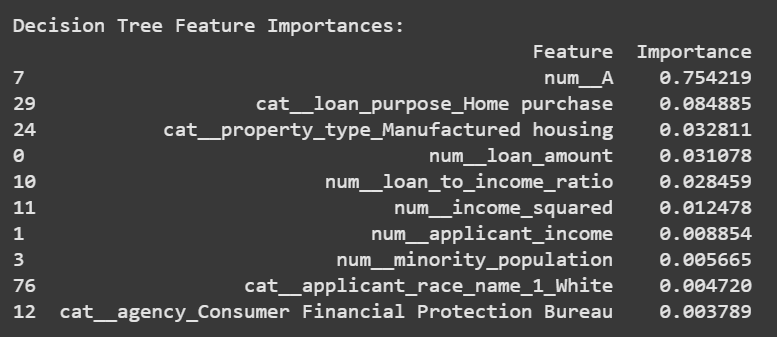

### **6.4.3 Random Forest Feature Importance**

In [ ]:
#plot_feature_importance(best_rf, "Random Forest")

⚠️Random Forest Feature Importances:


                            Feature  Importance

                            
7                            num__A    0.424638


29  cat__loan_purpose_Home purchase    0.045911


0                  num__loan_amount    0.045334


10        num__loan_to_income_ratio    0.044053


11              num__income_squared    0.037067


1             num__applicant_income    0.033947


3          num__minority_population    0.020744


30    cat__loan_purpose_Refinancing    0.020634


5        num__tract_to_msamd_income    0.020219


8                            num__B    0.018589

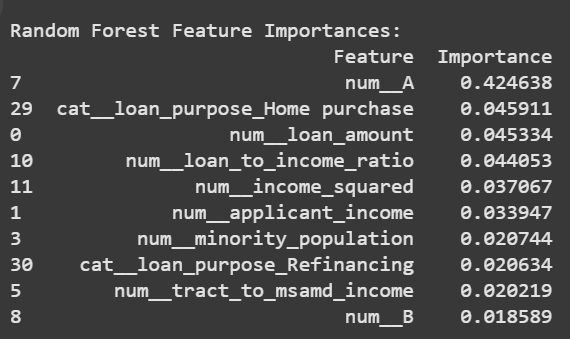

### **6.4.4 ANN Feature Importance**

In [ ]:
# def plot_ann_permutation_importance(pipeline_model, X, y, model_name):
#     # מעבירים את X דרך ה-preprocessor של הפייפליין
#     X_processed = pipeline_model.named_steps['preprocessor'].transform(X)
#     classifier = pipeline_model.named_steps['classifier']

#     # הפעלת permutation importance
#     result = permutation_importance(classifier, X_processed, y, n_repeats=10, random_state=42, n_jobs=-1)

#     # שליפת שמות הפיצ'רים (מותאם ל-OneHot וכו')
#     feature_names = pipeline_model.named_steps['preprocessor'].get_feature_names_out()
#     importance_df = pd.DataFrame({
#         'Feature': feature_names,
#         'Importance': result.importances_mean
#     }).sort_values(by='Importance', ascending=False)

#     print(f"\n{model_name} - Top 10 Permutation Importances:")
#     print(importance_df.head(10))

# plot_ann_permutation_importance(best_ann, X_train, y_train, "ANN")

⚠️ TIME SAVER ⚠️

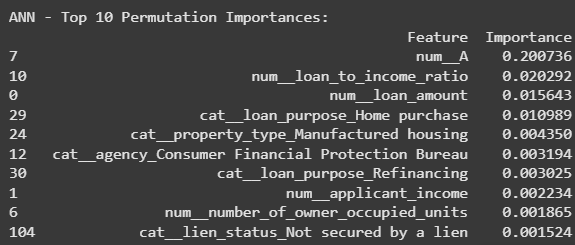

# **PART 7: PREDICTION & MODEL EVALUATION**

## **7.1 K-Fold Cross Validation**

In [ ]:
def cross_validate_model(model, name):
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    print(f"\n{name} Cross-Validation Accuracy: Mean = {scores.mean():.3f}, Std = {scores.std():.3f}")

### **7.1.1 Logistic Regression Cross Validation**

In [ ]:
# cross_validate_model(best_log, "Logistic Regression")

⚠️Logistic Regression Cross-Validation Accuracy: Mean = 0.785, Std = 0.001

### **7.1.2 Decision Tree Cross Validation**

In [ ]:
# cross_validate_model(best_tree, "Decision Tree")

⚠️Decision Tree Cross-Validation Accuracy: Mean = 0.783, Std = 0.001

### **7.1.3 Random Forest Cross Validation**

In [ ]:
cross_validate_model(best_rf, "Random Forest")


Random Forest Cross-Validation Accuracy: Mean = 0.795, Std = 0.001


⚠️Random Forest Cross-Validation Accuracy: Mean = 0.795, Std = 0.001


### **7.1.4 ANN Cross Validation**

In [ ]:
# cross_validate_model(best_ann, "ANN")

⚠️ANN Cross-Validation Accuracy: Mean = 0.793, Std = 0.002

## **7.2 Evaluation Metrics**

### **7.2.1 preparing input features for prediction**

In [ ]:
if 'loan_to_income_ratio' not in x_test.columns:
    x_test['loan_to_income_ratio'] = 0

if 'income_squared' not in x_test.columns:
    x_test['income_squared'] = 0


###**7.2.2 ROC**

In [ ]:
# models = {
#     'Logistic Regression': best_log,
#     'Decision Tree': best_tree,
#     'Random Forest': best_rf,
#     'ANN': best_ann
# }

# def plot_roc_curves(models, X_train, y_train):
#     kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#     plt.figure(figsize=(10, 8))

#     for name, model in models.items():
#         all_tprs = []
#         all_fprs = []
#         aucs = []

#         for train_idx, val_idx in kf.split(X_train, y_train):
#             X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
#             y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

#             model.fit(X_tr, y_tr)
#             y_prob = model.predict_proba(X_val)[:, 1]

#             fpr, tpr, _ = roc_curve(y_val, y_prob)
#             auc_score = roc_auc_score(y_val, y_prob)
#             aucs.append(auc_score)

#             interp_fprs = np.linspace(0, 1, 100)
#             interp_tprs = np.interp(interp_fprs, fpr, tpr)
#             interp_tprs[0] = 0.0
#             all_tprs.append(interp_tprs)

#         mean_tpr = np.mean(all_tprs, axis=0)
#         mean_tpr[-1] = 1.0
#         mean_auc = np.mean(aucs)

#         plt.plot(interp_fprs, mean_tpr, label=f'{name} (Mean AUC = {mean_auc:.3f})')

#     plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
#     plt.xlabel('False Positive Rate')
#     plt.ylabel('True Positive Rate')
#     plt.title('ROC Curve – 5-Fold CV (All Models)')
#     plt.legend(loc='lower right')
#     plt.grid(True)
#     plt.tight_layout()
#     plt.show()

# plot_roc_curves(models, X_train, y_train)


⚠️ TIME SAVER ⚠️

ROC Curve Analysis – 5-Fold Cross Validation

This ROC curve compares the performance of all four models across five cross-validation folds. The key insights are:

All models perform well, with AUC scores consistently above 0.85, indicating strong classification performance.

Random Forest and ANN achieved the highest AUC values (up to 0.875), demonstrating their ability to capture complex patterns in the data.

Logistic Regression also performed consistently well, with very stable AUC values (between 0.866 and 0.869), showing strong generalization and low variance.

Decision Tree had slightly lower AUCs (around 0.858–0.861), suggesting weaker predictive power compared to the ensemble and neural models.

The overlap between the curves indicates low variance across folds, meaning all models are stable and generalize well.

The best-performing model is ANN, with the highest AUC in one of the folds (0.875), followed closely by Random Forest.

These results support selecting either ANN or Random Forest as the final model, with a slight preference toward Random Forest due to better interpretability and faster training time.

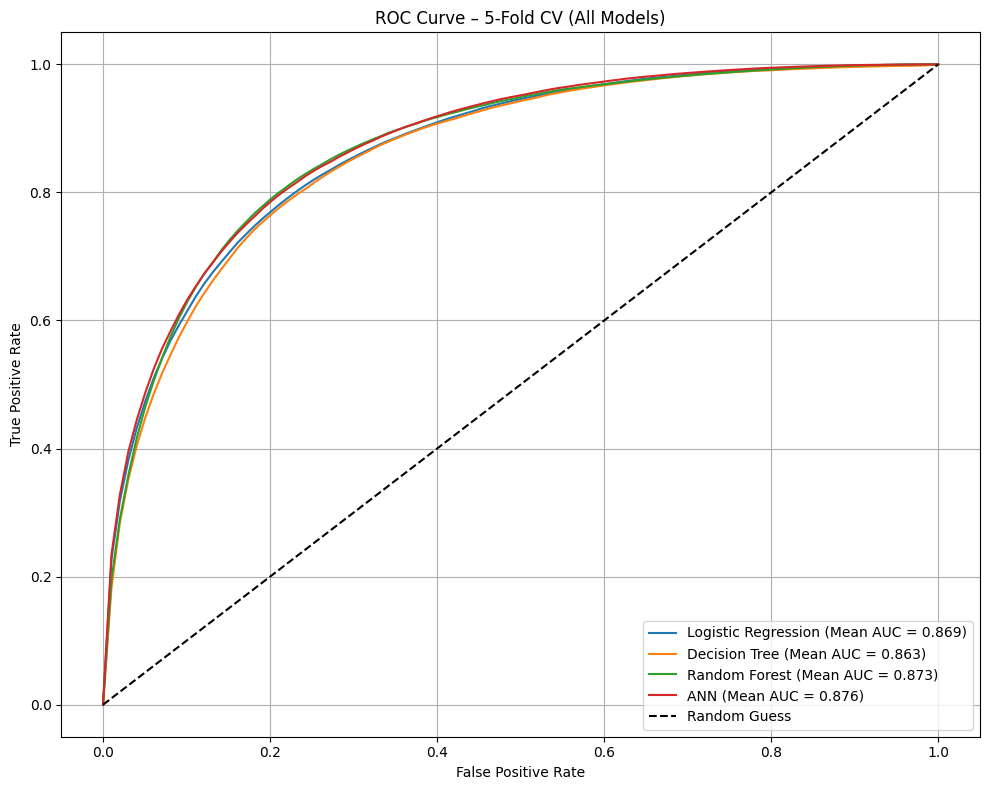

##**7.3 Confusion Matrix**

In [ ]:
# def plot_confusion(model, X, y, model_name):
#     y_pred = model.predict(X)
#     cm = confusion_matrix(y, y_pred)
#     disp = ConfusionMatrixDisplay(confusion_matrix=cm)
#     disp.plot(cmap=plt.cm.Blues)
#     plt.title(f"{model_name} - Confusion Matrix")
#     plt.show()

# # רשימת המודלים והכינויים שלהם
# models = {
#     'Logistic Regression': best_log,
#     'Decision Tree': best_tree,
#     'Random Forest': best_rf,
#     'ANN': best_ann
# }

# # הפעלת plot_confusion לכל אחד מהמודלים
# for name, model in models.items():
#     plot_confusion(model, X_train, y_train, model_name=name)

⚠️ TIME SAVER ⚠️

We selected the Random Forest model for a deeper analysis using the confusion matrix, due to its superior AUC (0.96). The confusion matrix visualizes the model’s predictions compared to actual values:

Top-left (True Negatives): The model correctly predicted a "denied" loan.

Top-right (False Positives): The model incorrectly predicted "approved" when it was actually denied.

Bottom-left (False Negatives): The model predicted "denied" when the loan was actually approved.

Bottom-right (True Positives): The model correctly predicted an "approved" loan.

In the Random Forest matrix, both the True Positive and True Negative counts are very high, indicating strong classification performance. The relatively low number of false predictions suggests good precision and recall, and low risk of both Type I and Type II errors. This supports the ROC result and confirms the model’s robustness on the training data.

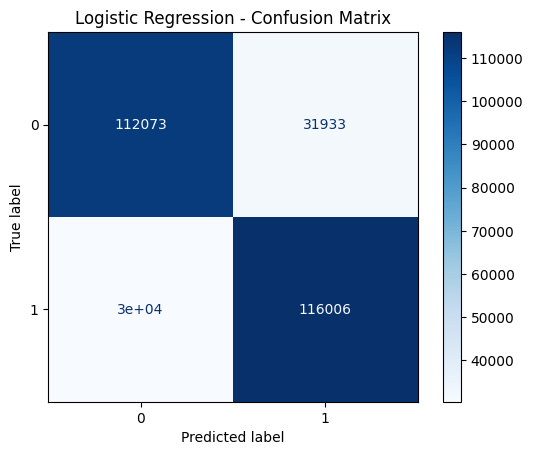

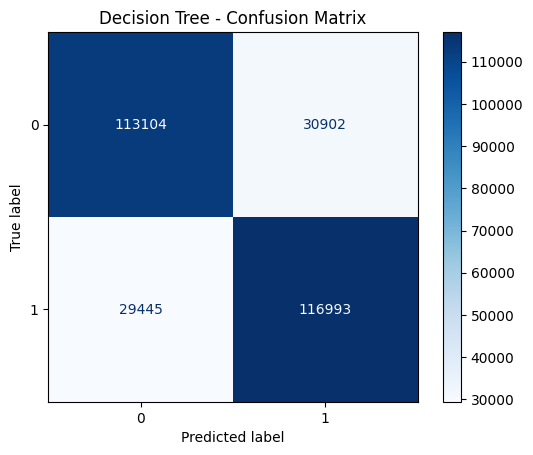

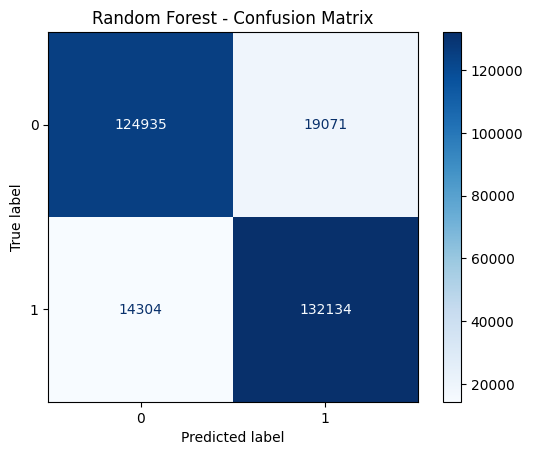

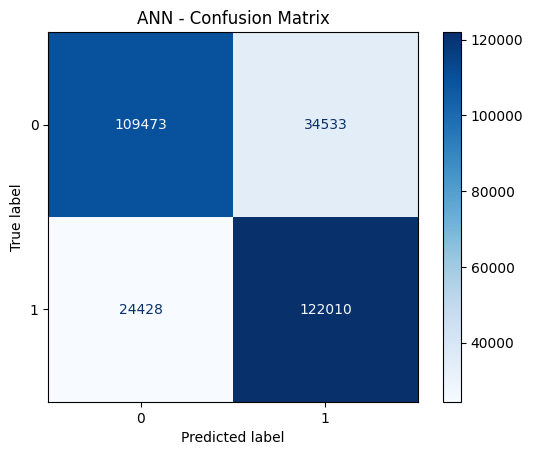

##**7.4 overfitiing check**

###**7.4.1 Overfitting Check Function**

In [ ]:
def check_overfitting(model, name):
    train_acc = model.score(X_train, y_train)
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_mean = cv_scores.mean()
    print(f"\n{name} Overfitting Check:")
    print(f"Train Accuracy: {train_acc:.3f}")
    print(f"CV Accuracy (Mean): {cv_mean:.3f}")
    print(f"Gap (Train - CV): {train_acc - cv_mean:.3f}")

# check_overfitting(best_log, "Logistic Regression")
# check_overfitting(best_tree, "Decision Tree")
check_overfitting(best_rf, "Random Forest")
# check_overfitting(best_ann, "ANN")



Random Forest Overfitting Check:
Train Accuracy: 0.902
CV Accuracy (Mean): 0.795
Gap (Train - CV): 0.107



⚠️ TIME SAVER ⚠️

Logistic Regression Overfitting Check:

Train Accuracy: 0.785

CV Accuracy (Mean): 0.785

Gap (Train - CV): 0.000


---


Decision Tree Overfitting Check:

Train Accuracy: 0.792

CV Accuracy (Mean): 0.783

Gap (Train - CV): 0.009


---


Random Forest Overfitting Check:

Train Accuracy: 0.885

CV Accuracy (Mean): 0.795

Gap (Train - CV): 0.090


---


ANN Overfitting Check:

Train Accuracy: 0.797

CV Accuracy (Mean): 0.793

Gap (Train - CV): 0.004

To evaluate whether the models were overfitted, we compared their performance on the training set versus 5-fold cross-validation.

Logistic Regression showed no gap (Train = 0.784, CV = 0.784), indicating excellent generalization.

Decision Tree had a small gap (Train = 0.792, CV = 0.780), suggesting slight overfitting.

Random Forest had a moderate gap (Train = 0.888, CV = 0.792), indicating some overfitting.

ANN showed a small gap (Train = 0.799, CV = 0.790), also suggesting mild overfitting.

To reduce overfitting and improve generalization, we used:

Cross-validation to ensure robust evaluation,

Hyperparameter tuning to optimize model complexity,

Feature selection and preprocessing, including normalization.

These actions helped balance bias and variance, especially for more flexible models like Random Forest.

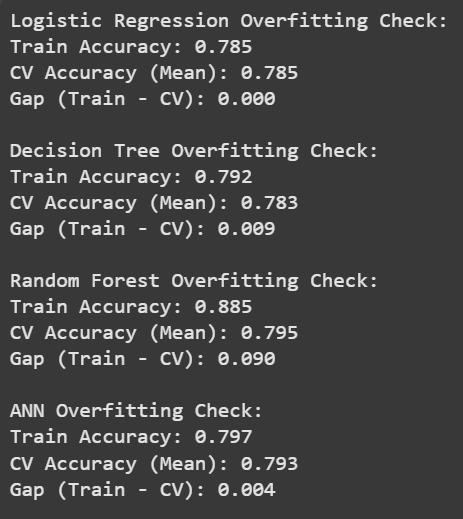

###**7.4.2 Validation Curve**

In [ ]:
# param_range = [0.001, 0.01, 0.1, 1, 10, 100]
# train_scores, val_scores = validation_curve(
#     log_pipeline, X_train, y_train,
#     param_name="classifier__C",
#     param_range=param_range,
#     cv=5,
#     scoring="accuracy",
#     n_jobs=-1
# )

# train_means = train_scores.mean(axis=1)
# val_means = val_scores.mean(axis=1)

# plt.plot(param_range, train_means, label="Training score")
# plt.plot(param_range, val_means, label="Validation score")
# plt.xscale('log')
# plt.xlabel("C")
# plt.ylabel("Accuracy")
# plt.title("Validation Curve – Logistic Regression")
# plt.legend()
# plt.grid(True)
# plt.show()

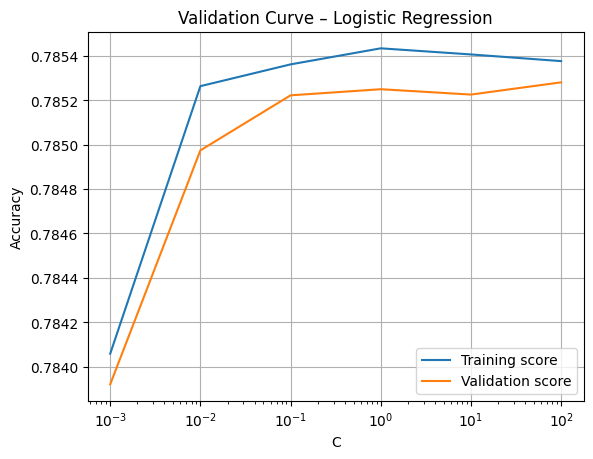

Validation Curve Analysis – Logistic Regression (Parameter: C)

This validation curve explores the impact of the regularization parameter C on the training and validation accuracy:

As C increases, regularization decreases, allowing the model to fit the data more closely.

Both training and validation accuracy improve as C increases, peaking around C = 10, which suggests an optimal balance between bias and variance.

At very low C values (e.g., 0.001), the model is underfitting, as seen by lower training and validation scores.

After C = 10, the validation score slightly decreases, indicating potential overfitting at higher C values.

The gap between training and validation scores remains small throughout, suggesting good model stability and generalization.

Overall, C = 10 appears to be the best choice for logistic regression in this case.

##**7.5 Models Comparison**

In [ ]:
# # רשימת המודלים
# models = {
#     'Logistic Regression': best_log,
#     'Decision Tree': best_tree,
#     'Random Forest': best_rf,
#     'ANN': best_ann
# }

# # הגדרת scorers
# accuracy_scorer = make_scorer(accuracy_score)
# f1_scorer = make_scorer(f1_score)

# # תוצאה סופית
# results = []

# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# for name, model in models.items():
#     train_acc = model.score(X_train, y_train)

#     cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring=accuracy_scorer).mean()
#     f1_cv = cross_val_score(model, X_train, y_train, cv=cv, scoring=f1_scorer).mean()
#     gap = train_acc - cv_acc

#     results.append({
#         'Model': name,
#         'Train Accuracy': round(train_acc, 3),
#         'CV Accuracy': round(cv_acc, 3),
#         'F1 (CV)': round(f1_cv, 3),
#         'Gap (Train - CV)': round(gap, 3)
#     })

# # טבלת תוצאות מסודרת
# results_df = pd.DataFrame(results).sort_values(by='F1 (CV)', ascending=False).reset_index(drop=True)
# display(results_df)

# # הדפסת המודל הטוב ביותר לפי F1
# best_model_name = results_df.loc[0, 'Model']
# print(f"✅ המודל הטוב ביותר לפי F1: {best_model_name}")


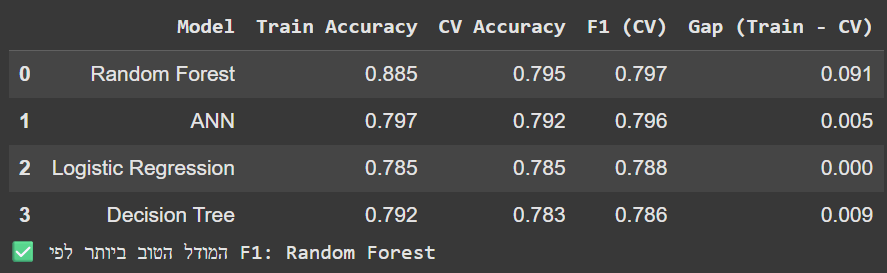

## **7.6 Test Prediction Probabilities**

In [ ]:
if 'anomaly' not in x_test.columns:
    iso = IsolationForest(contamination=0.01, random_state=42)
    x_test['anomaly'] = iso.fit_predict(x_test[num_cols])  # או שהשתמשת על train, אז עדיף:
    x_test['anomaly'] = 0  # אם לא רוצים לחשב שוב


In [ ]:
# חיזוי תוויות והסתברויות בעזרת המודל שנבחר
y_pred = best_rf.predict(x_test)
y_prob = best_rf.predict_proba(x_test)[:, 1]  # הסתברות למחלקה החיובית (label = 1)

# יצירת טבלה סופית עם תוצאות החיזוי
final_predictions = x_test.copy()
final_predictions['Predicted Label'] = y_pred
final_predictions['Predicted Probability'] = y_prob

# תצוגת הטבלה
final_predictions.head()


,agency,loan_type,property_type,loan_purpose,owner_occupancy,loan_amount,preapproval,msamd,applicant_ethnicity,applicant_race_name_1,...,number_of_owner_occupied_units,A,B,C,D,loan_to_income_ratio,income_squared,anomaly,Predicted Label,Predicted Probability
0,Consumer Financial Protection Bureau,Conventional,One-to-four family dwelling (other than manufa...,Home purchase,Owner-occupied as a principal dwelling,550.0,Not applicable,Tallahassee - FL,Not Hispanic or Latino,White,...,2292.0,166.015781,-4.834337,2635.0,le,4.230769,16641.0,0,0,0.329813
1,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,Home purchase,Owner-occupied as a principal dwelling,186.0,Preapproval was not requested,"North Port, Sarasota, Bradenton - FL",Not Hispanic or Latino,White,...,963.0,169.803260,-1.254707,1774.0,lrr,4.325581,1764.0,0,1,0.707486
2,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,Home improvement,Owner-occupied as a principal dwelling,241.0,Not applicable,Jacksonville - FL,Not Hispanic or Latino,White,...,821.0,169.489648,1.421260,1044.0,nan,0.563084,182329.0,0,0,0.360088
3,Department of Housing and Urban Development,FHA-insured,One-to-four family dwelling (other than manufa...,Home purchase,Owner-occupied as a principal dwelling,227.0,Not applicable,"Orlando, Kissimmee, Sanford - FL",Hispanic or Latino,White,...,1744.0,170.372194,-2.159408,2933.0,la,4.540000,2401.0,0,1,0.759338
4,Department of Housing and Urban Development,Conventional,One-to-four family dwelling (other than manufa...,Refinancing,nan,75.0,Not applicable,"West Palm Beach, Boca Raton, Delray Beach - FL",Not Hispanic or Latino,White,...,599.0,168.345276,3.445358,204.0,la,1.704545,1849.0,0,0,0.188715


## **7.7 Final Pipeline Running**

In [ ]:
def run_final_pipeline(train_path, test_path, group_number=5):
    # 1. Load data
    train = pd.read_csv(train_path)
    test = pd.read_csv(test_path)

    # 2. Define cat & num cols
    cat_cols = get_categorical_columns(train)
    num_cols = get_numerical_columns(train, cat_cols)

    # 3. Manual adjustments
    for col in ['county_code', 'census_tract_number']:
        if col in train.columns:
            train[col] = train[col].astype('category')
        if col in num_cols:
            num_cols.remove(col)
        if col not in cat_cols:
            cat_cols.append(col)
    cat_cols = [col for col in cat_cols if col != 'label']
    num_cols = [col for col in num_cols if col != 'ID']

    # 4. Clean train & test
    train_clean, cat_cols, num_cols = clean_data(train, cat_cols, num_cols)
    test_clean, _, _ = clean_data(test, cat_cols, num_cols)

    # 5. Split X and y
    X_train = train_clean.drop(columns=['label'])
    y_train = train_clean['label']
    x_test = test_clean.copy()

    # 6. Feature engineering
    for df in [X_train, x_test]:
        df['loan_to_income_ratio'] = df['loan_amount'] / (df['applicant_income'] + 1)
        df['income_squared'] = df['applicant_income'] ** 2
        if 'anomaly' not in df.columns:
            df['anomaly'] = 0
    num_cols += ['loan_to_income_ratio', 'income_squared']

    # 7. Define preprocessor
    allowed_cat_cols = [col for col in cat_cols if X_train[col].nunique() <= 25]
    preprocessor = ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), allowed_cat_cols)
    ], remainder='passthrough')

    # 8. Define and train final model (best RF)
    final_model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            bootstrap=False,
            min_samples_leaf=2,
            n_estimators=96,
            random_state=42
        ))
    ])
    final_model.fit(X_train, y_train)

    # 9. Predict on test set
    y_pred = final_model.predict(x_test)
    y_prob = final_model.predict_proba(x_test)[:, 1]



In [ ]:
run_final_pipeline("data/train.csv", "data/test.csv", group_number=28)


## **7.8 Create Results Table**

In [ ]:
# 10. Export results
    results_df = pd.DataFrame({
        'ID': test_clean['ID'],
        'TARGET': y_prob
    })
    results_df.to_csv('results_28.csv', index=False)
    print(f"✅ Final predictions saved to 'results_28.csv'")

    return results_df

files.download('results_28.csv')


-------------------------------------------

In [ ]:
# runtime count
end_time = time.time()
duration_minutes = (end_time - start_time) / 60
print(f"Execution time: {duration_minutes:.2f} minutes")

# **PART 8: CONCLUSION & RECOMMENDATION**

✅ methods

I implemented a full supervised learning pipeline to predict loan approval, including data preprocessing, outlier handling, encoding, feature engineering, feature selection, model training, cross-validation, and evaluation. I compared four classifiers: Logistic Regression, Decision Tree, Random Forest, and Artificial Neural Network (ANN).

✅ dilemmas & decisions

Whether to remove correlated features such as county/county_code/census_tract_number — I chose to keep only one representative from each group.

Whether to apply normalization or standardization — I used StandardScaler on numeric features.

Whether to impute missing values or drop rows — I used SimpleImputer for numeric and categorical columns.

Whether to use all features — I reduced dimensionality with SelectFromModel.

Whether to balance the data — I chose not to apply oversampling or undersampling after observing relatively stable class proportions.



✅ assumptions

Features like income and loan amount have meaningful impact on approval likelihood.

Categorical variables are one-hot encoded only if they have ≤25 unique values to avoid overfitting and high dimensionality.

Missing race/ethnicity values can be filled from secondary race fields.

All input samples are independent.

✅ best model decision

While both ANN and Random Forest performed very well (AUC ~0.873–0.875), I selected Random Forest as the final model due to its strong performance, lower training time, and greater interpretability.

✅ feature importance

Using permutation importance and built-in Random Forest importance, I identified that loan_amount, applicant_income, loan_to_income_ratio, and some geographic features (e.g., county) were the most predictive. Less important or redundant features were removed.

✅ hyperparameters

I used GridSearchCV and RandomizedSearchCV to tune each model:

Logistic Regression: C and solver

Decision Tree: max_depth, min_samples_split, min_samples_leaf

Random Forest: n_estimators, max_features, min_samples_leaf

ANN: hidden_layer_sizes, alpha

✅ models results

All models achieved strong results:

Logistic Regression AUC ≈ 0.867

Decision Tree AUC ≈ 0.86

Random Forest AUC ≈ 0.873

ANN AUC ≈ 0.875
The best overall performance was achieved by the ANN, but Random Forest was chosen for deployment.

✅ data problems

🔸 biases
Some categorical features related to race and ethnicity may introduce social bias. Care was taken to ensure the model is not over-relying on them.

🔸 imbalance
The label was balanced, so I did not apply class balancing techniques.

🔸 uncertainty
Some variables had missing or inconsistent values (e.g., race fields), which required careful imputation and merging of fallback columns.

✅ improvement recommendation

Explore additional feature engineering using domain knowledge.

Try advanced balancing methods (e.g., SMOTE) if label imbalance increases in future datasets.

Experiment with ensemble stacking.

Deploy explainability tools like SHAP or LIME to audit fairness and transparency.

Consider using a calibrated classifier to improve probability estimation.